📝 **Preview Notebook — Not for Re-execution**

This is a **GitHub-friendly preview version** of the full EDA and scoring notebook. It includes:

✅ Full visual outputs (charts, maps, scoring explanations)  
🚫 Not intended for re-running — variable state is not preserved across preview parts

> For full reproducibility, refer to the clean version:  
> `03b_eda_and_underinsured_score.ipynb` (outputs cleared, ready to run)
---

# 📊 Phase 3 – Exploratory Data Analysis & Underinsured Risk Score

**Notebook**: `03_eda_and_underinsured_score.ipynb`  
**Objective**: Explore the relationships between earthquake risk, insurance coverage, and demographic vulnerability across California counties. Derive a composite **underinsured risk score** to identify high-risk, underprotected regions.

---

### 📌 EDA Goals

- 📥 Load the cleaned dataset from the previous notebook  
- 📈 Visually and statistically explore relationships between key variables  
- 🕳️ Assess **coverage gaps** in high-risk earthquake zones  
- 🔍 Analyze interplay between:
  - 🧱 **Seismic hazard**  
    *(fault intersections, modeled loss, earthquake zone)*
  - 🛡️ **Insurance protection**  
    *(EQ take-up rate, homeowners insurance coverage, FEMA aid)*
  - 👥 **Socio-demographics**  
    *(poverty, housing age, seniors, household income, etc.)*
- 🧮 Derive a new composite variable: `underinsured_risk_score`

> This phase sets the foundation for **Phase 4: Predictive Modeling and Dashboard Visualizations**.

---

### 📤 Output Files

- `gdf_ca_scored_v4.geojson`: GeoJSON for mapping & visualization  
- `gdf_ca_scored_v4.parquet`: Full GeoDataFrame with types preserved (for modeling/EDA)  
📁 **Saved to**: `../output/`

---

### 🧾 Data Source

- ✅ **Input file**: `gdf_ca_cleaned.parquet`  
- 📁 **Filepath**: `../output/gdf_ca_cleaned.parquet`

---
## 📦 Load Packages


In [394]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns
import folium
from folium import Choropleth, CircleMarker, LayerControl
from branca.colormap import linear
from branca.element import Template, MacroElement
from scipy.stats import pearsonr, spearmanr
from sklearn.preprocessing import MinMaxScaler


---
## 📂 Data Loading


In [396]:
# Load from Parquet (preserves full Python types)
gdf = gpd.read_parquet("../output/gdf_ca_cleaned.parquet")

# Ensure faults_list is a native Python list (not NumPy array)
gdf["faults_list"] = gdf["faults_list"].apply(
    lambda x: x.tolist() if isinstance(x, np.ndarray) else x
)

# Basic Overview
print("Dataset loaded successfully")
print("Shape:", gdf.shape)
print("CRS:", gdf.crs)

# Type check for validation
print("\nColumn Type Check — faults_list:")
print(gdf["faults_list"].apply(type).value_counts())

gdf.head()


Dataset loaded successfully
Shape: (58, 59)
CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "NAD83", "datum": {"type": "GeodeticReferenceFrame", "name": "North American Datum 1983", "ellipsoid": {"name": "GRS 1980", "semi_major_axis": 6378137, "inverse_flattening": 298.257222101}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "direction": "east", "unit": "degree"}]}, "scope": "Geodesy.", "area": "North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illi

,county,total_population,median_income,age_0_17,age_18_64,age_65_up,age_0_17_pct,age_18_64_pct,age_65_up_pct,below_poverty,...,n_faults_intersecting,faults_list,centroid_to_fault_km,nearest_fault_km,fault_length_km,mean_fault_azimuth_deg,fault_orientation,land_area_m2,water_area_m2,geometry
0,Sierra,2731,60000,349,1440,942,12.8,52.7,34.5,325,...,4,"[Mohawk Valley fault zone, Polaris fault, Dog ...",7.55,0.00,107.44,103.31,E–W,2468694578,23299110,"POLYGON ((-120.55587 39.50874, -120.55614 39.5..."
1,Sacramento,1584047,88724,365667,981913,236467,23.1,62.0,14.9,197472,...,0,[],39.11,7.31,0.00,NaN,No Faults,2500063005,75323439,"POLYGON ((-121.43991 38.25553, -121.44002 38.2..."
2,Santa Barbara,443975,95977,99608,272385,71982,22.4,61.4,16.2,58387,...,25,"[Santa Cruz Island fault zone, Red Mountain fa...",2.21,0.00,826.05,131.90,NW–SE,7080874935,2729198796,"MULTIPOLYGON (((-120.58226 34.10752, -120.5790..."
3,Calaveras,45995,79877,7768,25007,13220,16.9,54.4,28.7,6083,...,1,[Foothills fault system],11.08,0.00,28.46,123.75,NW–SE,2641829627,43797225,"POLYGON ((-120.6318 38.34603, -120.63066 38.34..."
4,Ventura,838259,107327,185795,511149,141315,22.2,61.0,16.9,74630,...,29,"[Malibu Coast fault, Bailey fault, Chatsworth ...",5.17,0.00,746.63,83.01,E–W,4767585000,947376202,"MULTIPOLYGON (((-119.63607 33.28071, -119.6348..."


In [397]:
# Load seismic summary from Phase 1
eq_stats = pd.read_csv("../output/eq_stats_by_county.csv")

# Merge into main GeoDataFrame
gdf = gdf.merge(eq_stats, on="county", how="left")

# Confirm result
gdf[["county", "eq_count", "eq_mean_mag", "eq_max_mag"]].sort_values("eq_count", ascending=False).head(10)


,county,eq_count,eq_mean_mag,eq_max_mag
23,San Bernardino,509.0,4.45,7.5
20,Mono,374.0,4.44,6.8
32,Kern,354.0,4.45,7.5
48,Imperial,317.0,4.47,6.9
19,Inyo,204.0,4.51,7.4
5,Los Angeles,194.0,4.50,6.7
29,San Benito,186.0,4.51,6.5
31,Riverside,166.0,4.52,6.7
30,Humboldt,145.0,4.68,7.2
36,Fresno,115.0,4.41,6.7


---
## 📊 Part 1 – Dataset Overview & Initial Exploration

---
### 🔍 Dataset Overview 
Includes dataset structure, types, missing values, and merged seismic stats.

---
#### ➤ Dataset Structure & Types


In [399]:
gdf.info()


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 62 columns):
 #   Column                       Non-Null Count  Dtype   
---  ------                       --------------  -----   
 0   county                       58 non-null     object  
 1   total_population             58 non-null     int64   
 2   median_income                58 non-null     int64   
 3   age_0_17                     58 non-null     int64   
 4   age_18_64                    58 non-null     int64   
 5   age_65_up                    58 non-null     int64   
 6   age_0_17_pct                 58 non-null     float64 
 7   age_18_64_pct                58 non-null     float64 
 8   age_65_up_pct                58 non-null     float64 
 9   below_poverty                58 non-null     int64   
 10  below_poverty_pct            58 non-null     float64 
 11  white_alone_pct              58 non-null     float64 
 12  black_alone_pct              58 non-null     float64 
 13 

In [400]:
print("\nData Types Summary:")
print(gdf.dtypes.value_counts())

print("\nMissing Values (Top 10):")
print(gdf.isna().sum().sort_values(ascending=False).head(10))

print("\nColumn names:")
print(gdf.columns.tolist())

print("\nCounties in dataset:", gdf["county"].nunique())



Data Types Summary:
float64     30
int64       25
object       5
bool         1
geometry     1
Name: count, dtype: int64

Missing Values (Top 10):
mean_fault_azimuth_deg       6
eq_count                     4
eq_max_mag                   4
eq_mean_mag                  4
median_home_value            0
eq_policies                  0
eq_takeup_pct                0
eq_zone                      0
total_homeowners_policies    0
region                       0
dtype: int64

Column names:
['county', 'total_population', 'median_income', 'age_0_17', 'age_18_64', 'age_65_up', 'age_0_17_pct', 'age_18_64_pct', 'age_65_up_pct', 'below_poverty', 'below_poverty_pct', 'white_alone_pct', 'black_alone_pct', 'american_indian_alone_pct', 'asian_alone_pct', 'native_hawaiian_alone_pct', 'hispanic_pct', 'total_housing_units', 'built_pre_1980', 'built_1980_1999', 'built_2000_up', 'total_households', 'owner_occupied', 'renter_occupied', 'owner_pct', 'renter_pct', 'for_rent_pct', 'rented_not_occupied_pct', 'for_

In [401]:
# Check Missing Azimuth & Fault Info
missing_azimuth = gdf[gdf["mean_fault_azimuth_deg"].isna()]
missing_azimuth[["county", "intersects_fault", "n_faults_intersecting", "faults_list"]]


,county,intersects_fault,n_faults_intersecting,faults_list
1,Sacramento,False,0,[]
12,Mariposa,False,0,[]
33,Colusa,False,0,[]
34,Del Norte,False,0,[]
37,Madera,False,0,[]
49,Sutter,False,0,[]


In [402]:
# Display counties with missing earthquake stats
missing_quake_data = gdf[gdf["eq_count"].isna()]
missing_quake_data[["county", "eq_count", "eq_max_mag", "eq_mean_mag"]]


,county,eq_count,eq_max_mag,eq_mean_mag
3,Calaveras,NaN,NaN,NaN
28,Yuba,NaN,NaN,NaN
49,Sutter,NaN,NaN,NaN
50,Amador,NaN,NaN,NaN


In [403]:
# Fill missing quake stats with zeros
gdf["eq_count"] = gdf["eq_count"].fillna(0).astype(int)
gdf["eq_max_mag"] = gdf["eq_max_mag"].fillna(0)
gdf["eq_mean_mag"] = gdf["eq_mean_mag"].fillna(0)

gdf[["eq_count", "eq_max_mag", "eq_mean_mag"]].isna().sum()


eq_count       0
eq_max_mag     0
eq_mean_mag    0
dtype: int64

> ℹ️ **Note on Earthquake Stats:**  
> The following counties had **no recorded earthquakes** in the USGS dataset (1970–2020) and thus appear with zeros in `eq_count`, `eq_max_mag`, and `eq_mean_mag`:  
> • Calaveras  
> • Yuba  
> • Sutter  
> • Amador  
> These were originally `NaN` and filled with 0s to indicate absence of recorded seismic activity.


---
#### ➤ Summary Statistics


In [406]:
# Transposed Summary Table
(gdf.describe().T
    .style.format({"count": "{:,.0f}", "mean": "{:,.2f}", "std": "{:,.2f}",
                    "min": "{:,.2f}", "25%": "{:,.2f}", "50%": "{:,.2f}",
                    "75%": "{:,.2f}", "max": "{:,.2f}"})
    .set_caption("Summary Statistics (Formatted)")
)


,count,mean,std,min,25%,50%,75%,max
total_population,58,"676,599.74","1,443,820.84","1,695.00","48,214.50","186,926.50","696,887.50","9,848,406.00"
median_income,58,"87,001.14","25,546.76","53,498.00","67,888.50","80,701.50","102,701.25","159,674.00"
age_0_17,58,"150,500.21","307,486.45",349.00,"8,977.25","43,191.00","146,826.75","2,057,536.00"
age_18_64,58,"422,746.33","925,622.52",943.00,"26,316.75","107,329.00","433,364.75","6,342,299.00"
age_65_up,58,"103,353.21","212,357.78",369.00,"11,348.00","31,329.50","103,812.00","1,448,571.00"
age_0_17_pct,58,21.85,4.04,12.80,19.23,21.10,25.48,30.10
age_18_64_pct,58,59.18,4.00,49.80,56.92,59.55,61.70,69.10
age_65_up_pct,58,18.97,5.91,10.60,14.55,16.90,22.55,34.50
below_poverty,58,"79,493.10","184,772.75",209.00,"5,681.00","26,241.50","73,958.25","1,322,476.00"
below_poverty_pct,58,12.85,3.79,6.50,10.43,12.60,15.38,20.30


---
#### ➤ Selected Histograms


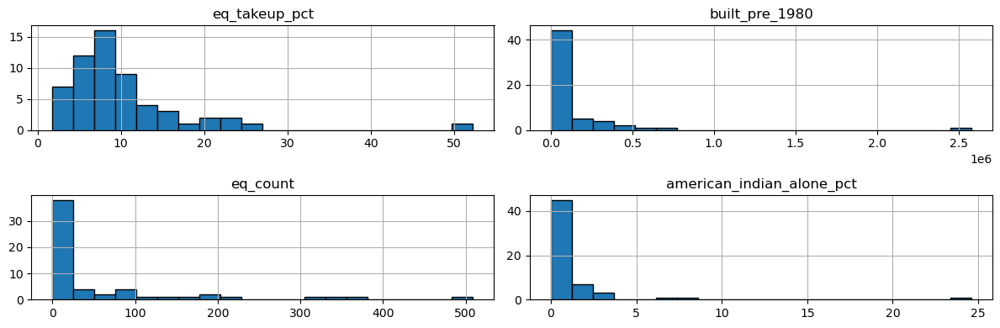

In [408]:
# Quick Histograms of Key Variables
gdf[["eq_takeup_pct", "built_pre_1980", "eq_count", "american_indian_alone_pct"]].hist(bins=20, figsize=(12, 4), edgecolor='black')

plt.tight_layout()
plt.savefig("../output/plot_hist_skewed_vars_quickview.png", dpi=300)


---
#### ➤ Fault Exposure by County


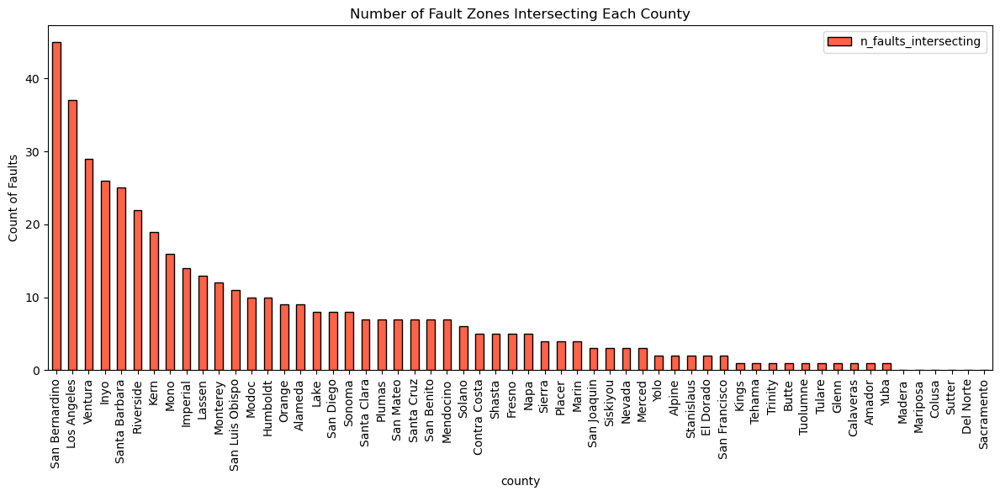

In [410]:
# Bar Chart of Fault Counts
gdf.sort_values("n_faults_intersecting", ascending=False).plot.bar(
    x="county", y="n_faults_intersecting", color="tomato", edgecolor="black",
    figsize=(12, 6), title="Number of Fault Zones Intersecting Each County")
plt.ylabel("Count of Faults")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("../output/plot_bar_fault_counts.png", dpi=300)
plt.show()


---
#### ➤ Seismic Risk Comparison: Fault Lines vs Earthquake Activity


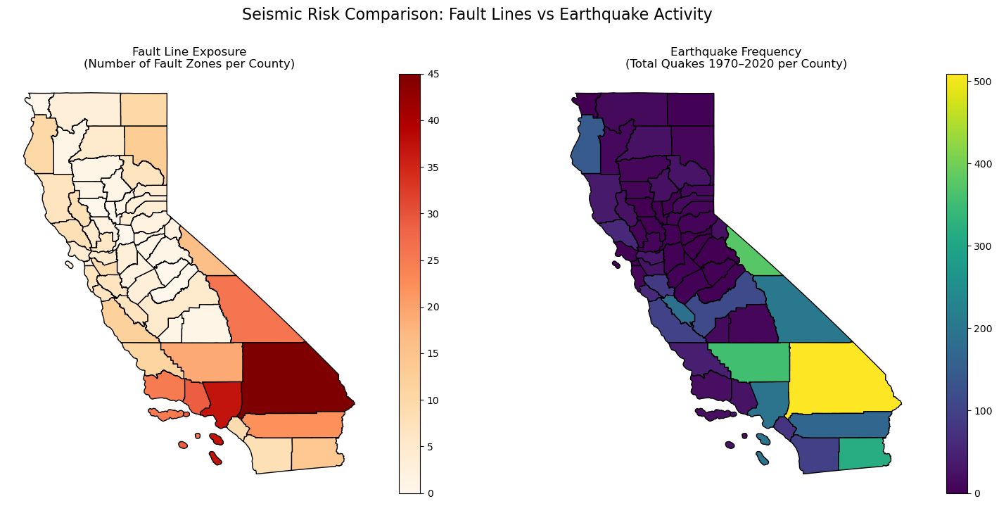

In [412]:
# Set up figure and axes
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Map 1: Fault Line Exposure ---
gdf.plot(
    column="n_faults_intersecting",
    cmap="OrRd",
    legend=True,
    edgecolor="black",
    ax=axes[0]
)
axes[0].set_title("Fault Line Exposure\n(Number of Fault Zones per County)")
axes[0].axis("off")

# --- Map 2: Earthquake Frequency ---
gdf.plot(
    column="eq_count",
    cmap="viridis",
    legend=True,
    edgecolor="black",
    ax=axes[1]
)
axes[1].set_title("Earthquake Frequency\n(Total Quakes 1970–2020 per County)")
axes[1].axis("off")

plt.suptitle("Seismic Risk Comparison: Fault Lines vs Earthquake Activity", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("../output/plot_fault_lines_vs_quake.png", dpi=300)
plt.show()


---
### 📈 Skewed Distributions – Identify High-Variance Variables  
- Function: `identify_high_spread_vars()`  
- Top 15 high-spread numeric variables

---
#### ➤ Identify High Spread Variables


In [414]:
# Preview variables with large spread
def identify_high_spread_vars(df, top_n=15):
    numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
    stats = df[numeric_cols].describe().T
    stats["spread_ratio"] = stats["max"] / stats["mean"]
    stats = stats.replace([np.inf, -np.inf], np.nan).dropna(subset=["spread_ratio"])
    return stats.sort_values("spread_ratio", ascending=False).round(2).head(top_n)

high_spread = identify_high_spread_vars(gdf, top_n=15)
high_spread[["count", "mean", "std", "max", "spread_ratio"]]


,count,mean,std,max,spread_ratio
fema_funding_earthquake,58.0,1624355.52,7098701.97,44114267.10,27.16
nearest_fault_km,58.0,1.10,4.32,27.21,24.74
built_pre_1980,58.0,142121.41,357082.81,2578211.00,18.14
american_indian_alone_pct,58.0,1.36,3.41,24.60,18.08
renter_occupied,58.0,102414.41,256118.00,1828047.00,17.85
renewed_fair,58.0,4008.33,10217.83,70465.00,17.58
below_poverty,58.0,79493.10,184772.75,1322476.00,16.64
eq_policies,58.0,28292.36,72106.76,458782.00,16.22
age_18_64,58.0,422746.33,925622.52,6342299.00,15.00
total_households,58.0,231635.29,494888.32,3390254.00,14.64


---
### 🏛️ Investigation of Skewed Variable — `fema_funding_earthquake`

In this section, I analyzed the amount of FEMA earthquake-related public assistance funding allocated to each California county. While not a direct predictor of earthquake insurance take-up, this variable offers insight into **where major seismic disasters have occurred** and how federal aid has been distributed over time.

---
#### ➤ Distribution of FEMA Earthquake Funding


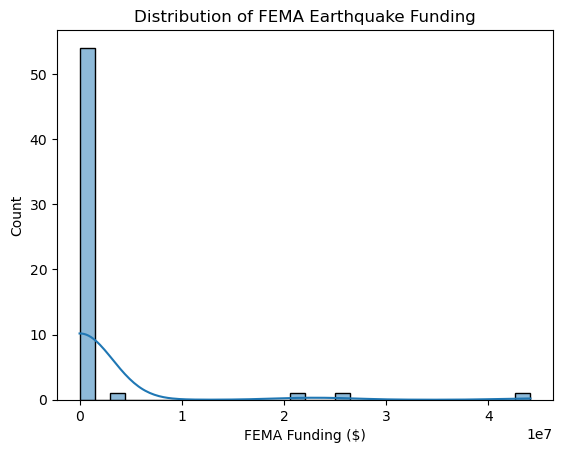

In [416]:
sns.histplot(gdf["fema_funding_earthquake"], bins=30, kde=True)
plt.title("Distribution of FEMA Earthquake Funding")
plt.xlabel("FEMA Funding ($)")
plt.show()


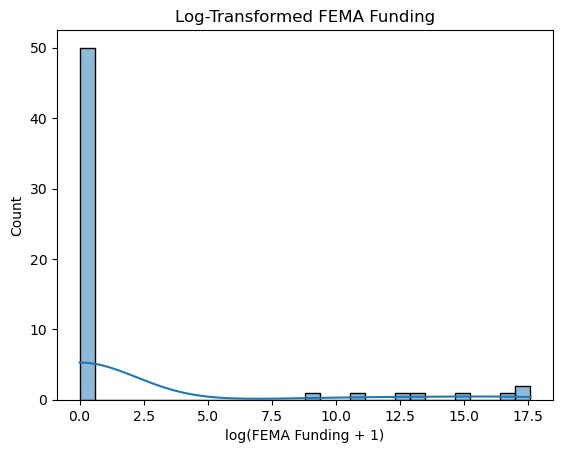

In [417]:
sns.histplot(np.log1p(gdf["fema_funding_earthquake"]), bins=30, kde=True)
plt.title("Log-Transformed FEMA Funding")
plt.xlabel("log(FEMA Funding + 1)")
plt.show()


> The distribution of `fema_funding_earthquake` is **highly right-skewed**.  
> - Most counties received **little or no FEMA funding** over the period of record  
> - A small number of counties received **very large amounts**, often following major seismic events  
> - The maximum recorded total exceeded **\$44 million**
>
> After applying a log transformation, the distribution becomes more normalized — but still reflects the **event-driven nature** of this variable
>
> This strongly suggests that FEMA funding is **reactive** (post-disaster), rather than tied to long-term seismic risk or baseline vulnerability.  
> As a result, I use this variable for **narrative exploration**, but **exclude it from modeling.**

---
#### ➤ FEMA Funding vs. Fault Line Proximity


In [419]:
# Are counties with high FEMA funding close to fault lines?
gdf[gdf["fema_funding_earthquake"] > 0][["county", "fema_funding_earthquake", "nearest_fault_km"]] \
    .sort_values(by="fema_funding_earthquake", ascending=False) \
    .head(10)  


,county,fema_funding_earthquake,nearest_fault_km
57,San Luis Obispo,44114267.10,0.00
48,Imperial,25023516.25,0.00
14,Napa,21048662.00,0.00
22,Solano,3096552.55,0.00
2,Santa Barbara,648440.19,0.00
0,Sierra,227958.95,0.00
1,Sacramento,44911.70,7.31
11,Marin,8311.40,0.00


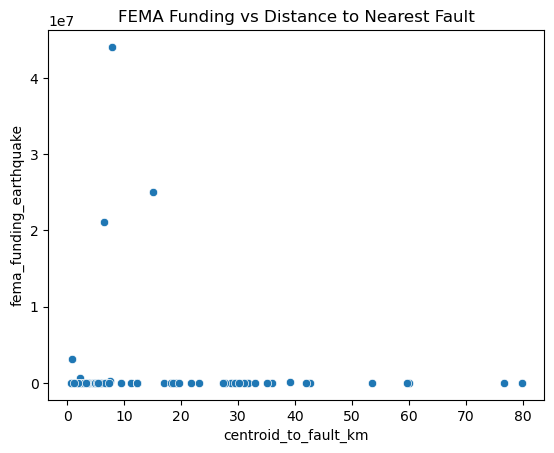

In [420]:
sns.scatterplot(
    data=gdf, 
    x="centroid_to_fault_km", 
    y="fema_funding_earthquake"
)
plt.title("FEMA Funding vs Distance to Nearest Fault")
plt.show()


> Counties that received the **largest FEMA earthquake allocations** are located **directly on or adjacent to major fault zones** — often with `nearest_fault_km = 0.00`.
>
> Examples include:
> - **San Luis Obispo**: \$44M
> - **Imperial**: \$25M
> - **Napa County**: \$21M (likely related to the 2014 South Napa Earthquake)
>
> These cases reinforce the idea that FEMA assistance is closely tied to **localized damage** caused by major seismic events — not by fault proximity alone.
>
> **Insight**: Proximity to faults is necessary but not sufficient for FEMA support — funding is conditional on **disaster declarations** following specific events.

---
#### ➤ FEMA Funding vs. Earthquake Frequency


In [422]:
# Earthquake frequency + FEMA funding preview
gdf[["county", "eq_count", "fema_funding_earthquake"]].sort_values(by="eq_count", ascending=False).head(10)


,county,eq_count,fema_funding_earthquake
23,San Bernardino,509,0.00
20,Mono,374,0.00
32,Kern,354,0.00
48,Imperial,317,25023516.25
19,Inyo,204,0.00
5,Los Angeles,194,0.00
29,San Benito,186,0.00
31,Riverside,166,0.00
30,Humboldt,145,0.00
36,Fresno,115,0.00


>**Key Observation**  
>Many of the counties with the **most frequent earthquakes** — including **San Bernardino (509)**, **Mono (374)**, and **Kern (354)** — received **no FEMA earthquake funding** at all.  
>In contrast, **Imperial County**, which ranked 4th in frequency (317 quakes), received over **\$25 million** in FEMA support. This suggests that:
>- FEMA does **not respond to frequency alone**  
>- **Magnitude**, **infrastructure damage**, and **population vulnerability** are critical in triggering federal assistance  
>- Counties with **frequent but low-impact quakes** (e.g., Mono, San Bernardino) may **not meet FEMA’s disaster declaration thresholds**  
>
>For example:
>- **Imperial** received funding likely due to structural impacts in population centers
>- **Napa County**, with fewer quakes overall, received **$21M** following a single high-impact event in 2014
>
>Insight: FEMA funding is more closely aligned with **disaster severity** than seismic frequency — reinforcing its role as a **reactive aid mechanism**, not a proxy for ongoing risk.


---
#### ➤ FEMA Earthquake Funding Map


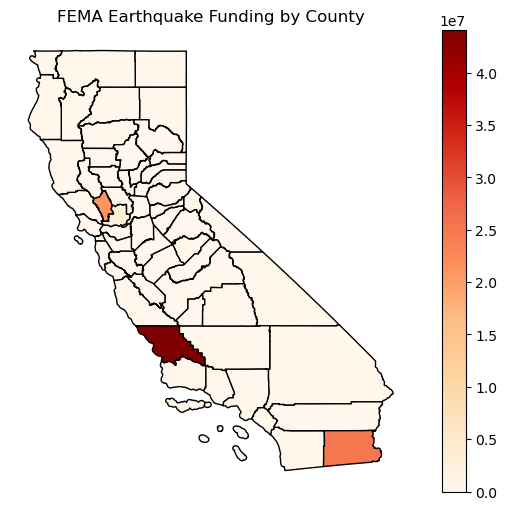

In [424]:
# FEMA Earthquake Funding Map
gdf.plot(
    column="fema_funding_earthquake", 
    cmap="OrRd", 
    legend=True, 
    edgecolor="black",
    figsize=(8, 6)
)
plt.title("FEMA Earthquake Funding by County")
plt.axis("off")
plt.savefig("../output/plot_fema.png", dpi=300)
plt.show()


> The funding map clearly illustrates a **clustered pattern**: only a handful of counties have received significant FEMA earthquake funds, with most of the state showing no historical allocation. These spatial disparities highlight the **event- and impact-specific nature** of FEMA’s role, and reinforce the decision to treat this variable as **contextual only**, not as a predictive feature.

---

#### ➤ ✅ Conclusion
- `fema_funding_earthquake` reflects **past disaster response**, not long-term exposure
- It is **not a reliable or generalizable input** for modeling earthquake insurance take-up
- I include this variable for **narrative storytelling and map visualization**, but **exclude it from the core predictive model**


---
### 📍 Investigation of Skewed Variable — `nearest_fault_km`

In this section, I evaluated two proximity-based variables related to fault lines:

- `nearest_fault_km`: minimum distance from any part of the county to the nearest fault line (may be 0 km if intersecting)
- `centroid_to_fault_km`: distance from the county centroid to the nearest fault line

My goal was to determine which of these variables better captures county-level exposure to seismic risk and helps explain variation in earthquake insurance take-up rates.

---
#### ➤ Distance to Nearest Fault Line (`nearest_fault_km`)


In [427]:
# Top counties farthest from fault lines (based on nearest_fault_km)
display(gdf[["county", "nearest_fault_km"]].sort_values("nearest_fault_km", ascending=False).head(10))


,county,nearest_fault_km
34,Del Norte,27.21
12,Mariposa,14.32
49,Sutter,11.28
1,Sacramento,7.31
33,Colusa,3.08
37,Madera,0.58
43,Butte,0.00
31,Riverside,0.00
32,Kern,0.00
35,Modoc,0.00


>I examined the `nearest_fault_km` variable to identify counties geographically farthest from fault lines:
>- **Del Norte County** has the maximum value: **27.21 km**
>- Many counties (e.g., **Butte, Riverside, Kern**) report **0.00 km**, indicating direct intersection
>- Urban counties like **Sacramento** show moderate distance (~7.3 km)
>- Counties such as **Mariposa** and **Sutter** fall into the 10–15 km range  
>  
>However, this variable exhibits **severe right skew**, with most counties tightly clustered near 0 km.

---

>#### ❌ Why I Didn't Use `nearest_fault_km`
>
> Despite initial exploration, I excluded `nearest_fault_km` from further analysis and modeling due to several limitations:
>- **Low variability** — Majority of counties report a value of **0.0 km**
>- **Redundancy** — Overlaps conceptually with `intersects_fault` (a boolean indicator already included)
>- **Weak explanatory power** — Does not effectively differentiate counties based on perceived seismic exposure
>
>Instead, I used `centroid_to_fault_km`, which provides a **continuous**, **non-zero**, and more **informative** measure of proximity to fault lines.

---
#### ➤ EQ Take-Up Rate vs. Centroid-to-Fault Distance


In [429]:
# Counties with farthest centroid-based distance
display(gdf[["county", "centroid_to_fault_km"]].sort_values("centroid_to_fault_km", ascending=False).head(10))


,county,centroid_to_fault_km
37,Madera,79.77
36,Fresno,76.60
12,Mariposa,59.90
34,Del Norte,59.55
17,Trinity,53.47
21,Tuolumne,42.62
54,Siskiyou,41.92
1,Sacramento,39.11
26,El Dorado,35.98
40,San Joaquin,34.99


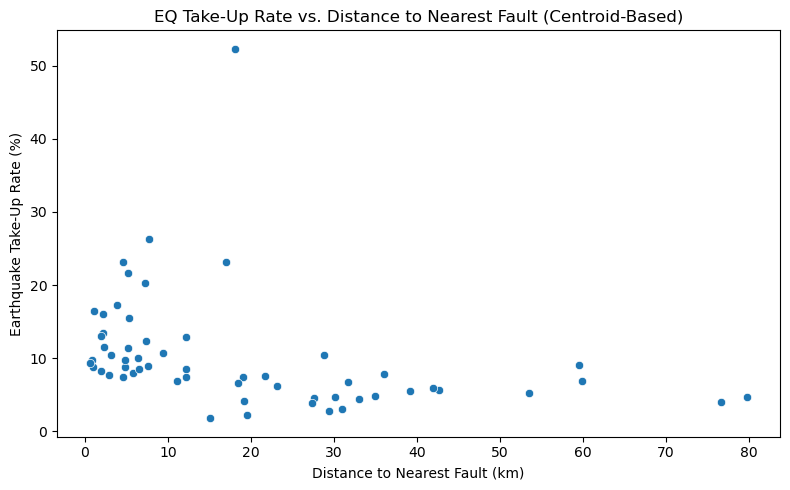

In [430]:
# Scatterplot: EQ Take-Up Rate vs. Distance to Fault
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=gdf, 
    x="centroid_to_fault_km", 
    y="eq_takeup_pct"
)
plt.title("EQ Take-Up Rate vs. Distance to Nearest Fault (Centroid-Based)")
plt.xlabel("Distance to Nearest Fault (km)")
plt.ylabel("Earthquake Take-Up Rate (%)")
plt.tight_layout()
plt.show()


> Based on the scatterplot, there is no clear linear relationship between `centroid_to_fault_km` and earthquake insurance take-up rates.  
> Counties located very close to fault lines (0–5 km) show a wide range of take-up rates, from under 2% to over 50%.  
> While I expected to see higher take-up rates in areas closer to faults, the scatter remains dispersed even at short distances.  
> This suggests that **proximity to fault lines alone does not strongly predict insurance behavior**, and other factors (e.g., income, awareness, housing type) may be more influential.


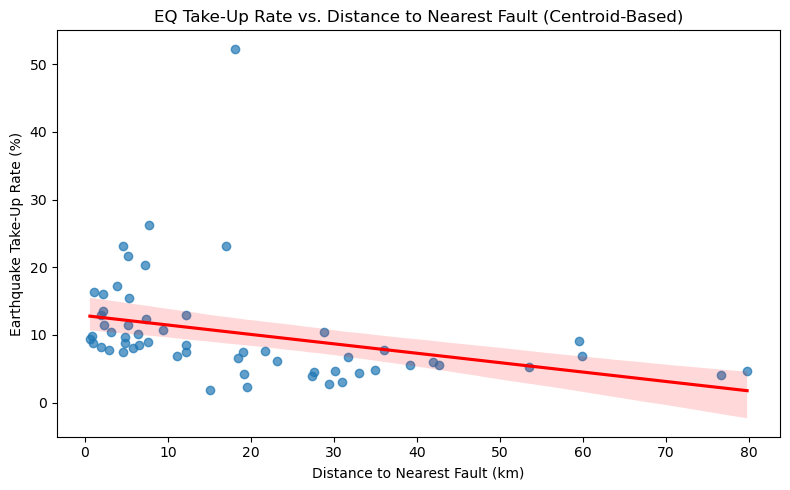

📉 Pearson Correlation: -0.34
📉 Spearman Correlation: -0.64


In [432]:
# Regression Scatterplot
plt.figure(figsize=(8, 5))
sns.regplot(
    data=gdf, 
    x="centroid_to_fault_km", 
    y="eq_takeup_pct",
    scatter_kws={'alpha': 0.7},
    line_kws={'color': 'red'}
)
plt.title("EQ Take-Up Rate vs. Distance to Nearest Fault (Centroid-Based)")
plt.xlabel("Distance to Nearest Fault (km)")
plt.ylabel("Earthquake Take-Up Rate (%)")
plt.tight_layout()
plt.show()

# Calculate correlation
pearson_corr = gdf["centroid_to_fault_km"].corr(gdf["eq_takeup_pct"], method="pearson")
spearman_corr = gdf["centroid_to_fault_km"].corr(gdf["eq_takeup_pct"], method="spearman")

print(f"📉 Pearson Correlation: {pearson_corr:.2f}")
print(f"📉 Spearman Correlation: {spearman_corr:.2f}")


> I added a regression line to assess whether there’s a trend between `centroid_to_fault_km` and earthquake insurance take-up rates.  
> Visually, the slope is slightly negative, but the scatter remains broad across all distance ranges.  
>
> To confirm this, I calculated both Pearson and Spearman correlations:
> - **Pearson**: -0.34
> - **Spearman**: -0.64
>
> These values indicate a **weak negative relationship** — suggesting that counties located farther from fault lines tend to have slightly lower take-up rates, but the association is not strong.  
> Overall, **fault proximity alone does not appear to be a reliable predictor** of take-up behavior and likely interacts with other demographic or socioeconomic variables.


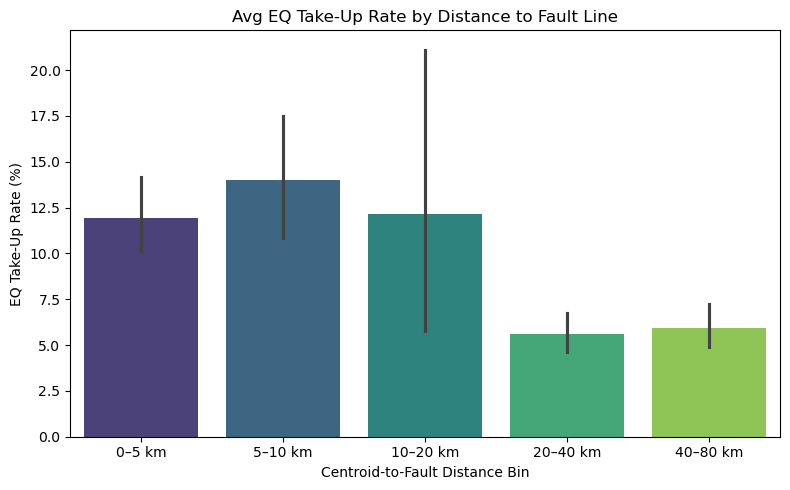

In [434]:
# Binned barplot of take-up rates by centroid distance
gdf["distance_bin"] = pd.cut(
    gdf["centroid_to_fault_km"],
    bins=[0, 5, 10, 20, 40, 80],
    labels=["0–5 km", "5–10 km", "10–20 km", "20–40 km", "40–80 km"])

plt.figure(figsize=(8, 5))
sns.barplot(
    data=gdf, 
    x="distance_bin", 
    y="eq_takeup_pct", 
    hue="distance_bin",
    palette="viridis", 
    legend=False
)
plt.title("Avg EQ Take-Up Rate by Distance to Fault Line")
plt.xlabel("Centroid-to-Fault Distance Bin")
plt.ylabel("EQ Take-Up Rate (%)")
plt.tight_layout()
plt.show()


>**Key Insight** — High Variance in 10–20 km Bin
>
>- This distance group shows the **widest error bars** in the barplot
>- Most counties in this bin range between **4–13%** take-up rate
>- But extreme values in counties like:
>   - **Mono County** → 52.3%
>   - **San Diego County** → 23.2%
>- Others like **Imperial** and **Glenn** fall below 2.5%
>
>These **outliers inflate the mean (~12%)** and highlight the importance of **examining distribution**, not just averages.

---

In [436]:
# View counties in the 10–20 km distance bin
gdf[gdf['distance_bin'] == '10–20 km'][['county', 'eq_takeup_pct']]


,county,eq_takeup_pct
3,Calaveras,6.9
6,Sonoma,12.9
7,Kings,8.5
8,San Diego,23.2
9,Placer,7.5
20,Mono,52.3
28,Yuba,7.4
46,Stanislaus,4.2
48,Imperial,1.8
50,Amador,6.6


---
#### ➤ ✅ Conclusion

- `nearest_fault_km` was excluded due to severe skew and limited usefulness
- `centroid_to_fault_km` provides more **granular**, **meaningful**, and **spatially distributed** insight into fault proximity
- This variable was retained for modeling and risk scoring
  

---
### 🏚️ Investigation of Skewed Variable — `built_pre_1980`

In this section, I examined the number and percentage of housing units built before 1980, a key proxy for structural vulnerability. Older homes are more likely to lack seismic retrofitting, making them more sensitive to earthquake damage — and potentially influencing insurance demand.

I focused on:
- Raw distribution and top counties
- Derived variable: `pre_1980_pct` (percent of total housing)
- Correlation with earthquake insurance take-up
- Outlier analysis (Mono County)
- County-level comparison chart
- ✅ *Conclusion: Moderate correlation, stronger without Mono*

---

#### ➤ Distribution of Pre-1980 Housing Units


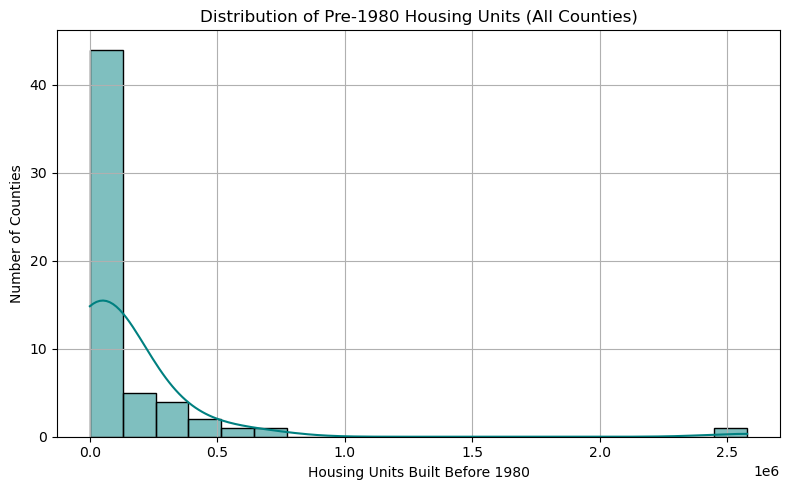

In [439]:
# Histogram: Distribution of pre-1980 housing units
plt.figure(figsize=(8, 5))
sns.histplot(gdf['built_pre_1980'], bins=20, kde=True, color='teal')
plt.title('Distribution of Pre-1980 Housing Units (All Counties)')
plt.xlabel('Housing Units Built Before 1980')
plt.ylabel('Number of Counties')
plt.grid(True)
plt.tight_layout()
plt.show()


> The distribution of `built_pre_1980` is highly right-skewed, with most counties falling below 100,000 older units.  
> A small number of large-population counties dominate the upper tail — particularly Los Angeles.

---
#### ➤ Top Counties by Pre-1980 Units


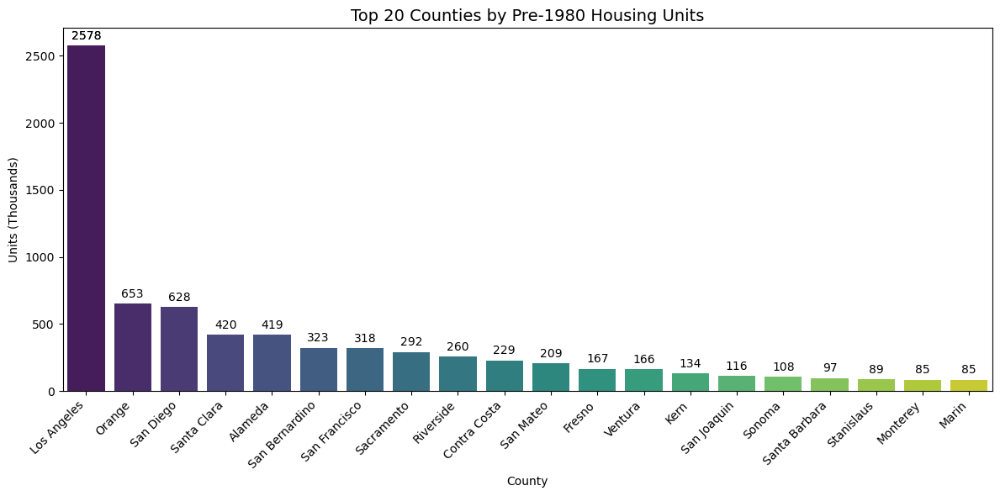

In [441]:
# Top 20 Counties with Most Pre-1980 Units (in thousands)
top_n = 20
gdf_sorted = gdf.sort_values("built_pre_1980", ascending=False).head(top_n)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=gdf_sorted,
    x="county",
    hue="county",
    y=gdf_sorted["built_pre_1980"] / 1000,
    palette="viridis"
)
ax.set_title("Top 20 Counties by Pre-1980 Housing Units", fontsize=14)
ax.set_ylabel("Units (Thousands)")
ax.set_xlabel("County")
plt.xticks(rotation=45, ha='right')
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, label_type="edge")
plt.tight_layout()
plt.show()


> **Los Angeles County** is a major outlier, with over **2.5 million** pre-1980 housing units — nearly **4x** more than any other county.  
> This dominant stock of legacy buildings may affect both seismic vulnerability and insurance behavior, especially if retrofitting policies are unevenly enforced or adopted.

---
#### ➤ Derived Variable: `pre_1980_pct`


In [443]:
# Add % of Pre-1980 Housing
gdf["pre_1980_pct"] = (gdf["built_pre_1980"] / gdf["total_housing_units"]) * 100
gdf["pre_1980_pct"] = gdf["pre_1980_pct"].round(2)
gdf[["county","pre_1980_pct"]].sort_values("pre_1980_pct", ascending=False).head(10)


,county,pre_1980_pct
10,San Francisco,77.21
11,Marin,76.11
53,San Mateo,73.33
5,Los Angeles,71.14
41,Alameda,66.39
55,Santa Cruz,63.74
19,Inyo,63.35
2,Santa Barbara,60.82
30,Humboldt,60.47
38,Santa Clara,60.43


> I calculated the share of older housing (`pre_1980_pct`) by dividing pre-1980 units by total housing stock in each county.  
> This normalized metric removes size bias and provides a better basis for comparing counties of different sizes.

---
#### ➤ Correlation with EQ Take-Up Rate


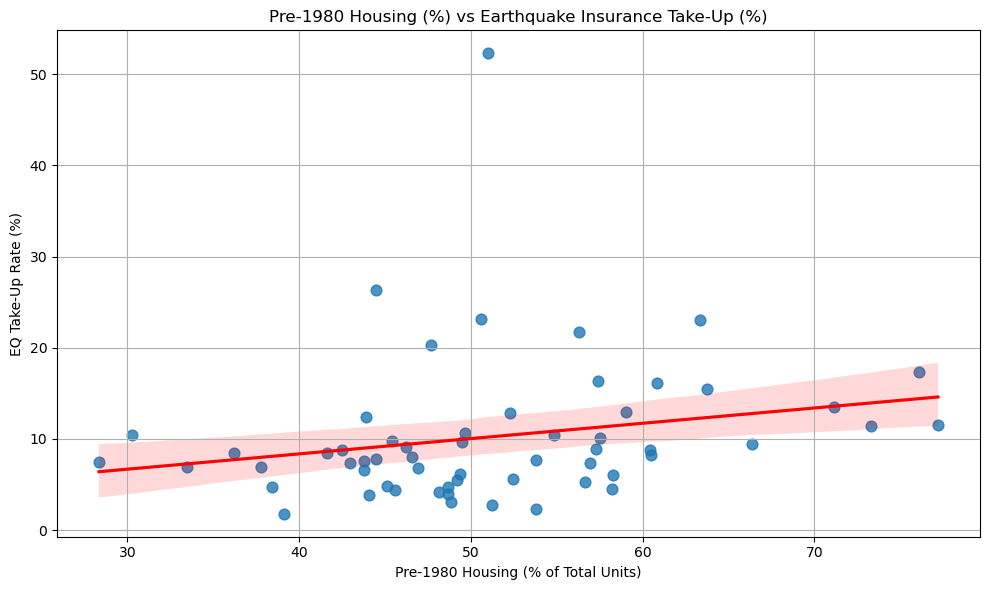

In [445]:
# Scatterplot: Pre-1980 Housing % vs EQ Take-Up %
plt.figure(figsize=(10, 6))
sns.regplot(
    data=gdf,
    x="pre_1980_pct",
    y="eq_takeup_pct",
    scatter_kws={"s": 60, "alpha": 0.8},
    line_kws={"color": "red"},
)
plt.title("Pre-1980 Housing (%) vs Earthquake Insurance Take-Up (%)")
plt.xlabel("Pre-1980 Housing (% of Total Units)")
plt.ylabel("EQ Take-Up Rate (%)")
plt.grid(True)
plt.tight_layout()
plt.show()


> The scatterplot suggests a **positive relationship** between `pre_1980_pct` and earthquake insurance take-up:  
> - Counties with a **higher share of older homes** generally report **higher insurance take-up rates**
> - However, the pattern is not tightly linear — there is visible dispersion across the middle of the distribution

---
#### ➤ Outlier Analysis: Mono County


In [447]:
# Correlation Summary (with/without Mono County)
pearson_full = gdf["pre_1980_pct"].corr(gdf["eq_takeup_pct"], method="pearson")
spearman_full = gdf["pre_1980_pct"].corr(gdf["eq_takeup_pct"], method="spearman")

gdf_no_mono = gdf[gdf["county"] != "Mono"]
pearson_no_mono = gdf_no_mono["pre_1980_pct"].corr(gdf_no_mono["eq_takeup_pct"], method="pearson")
spearman_no_mono = gdf_no_mono["pre_1980_pct"].corr(gdf_no_mono["eq_takeup_pct"], method="spearman")

print(f"Pearson (with Mono): {pearson_full:.2f}")
print(f"Pearson (no Mono) : {pearson_no_mono:.2f}")
print(f"Spearman (with Mono): {spearman_full:.2f}")
print(f"Spearman (no Mono) : {spearman_no_mono:.2f}")


Pearson (with Mono): 0.22
Pearson (no Mono) : 0.32
Spearman (with Mono): 0.36
Spearman (no Mono) : 0.36


> **Mono County** is a clear outlier, with:
> - **52.3%** earthquake insurance take-up (highest in the state)
> - **51.0%** of housing units built before 1980  
>
> To evaluate its impact, I computed Pearson and Spearman correlations with and without Mono County:
>
> - **Pearson correlation** increased from **0.22 → 0.32** (Mono lowers the linear strength)
> - **Spearman correlation** stayed constant at **0.36**
>
> This suggests that **Mono inflates variance**, weakening the linear association — although the rank-based (monotonic) trend holds.  
> I may consider flagging or down-weighting such outliers in future modeling.

---
#### ➤ County Comparison: Pre-1980 Housing vs EQ Take-Up


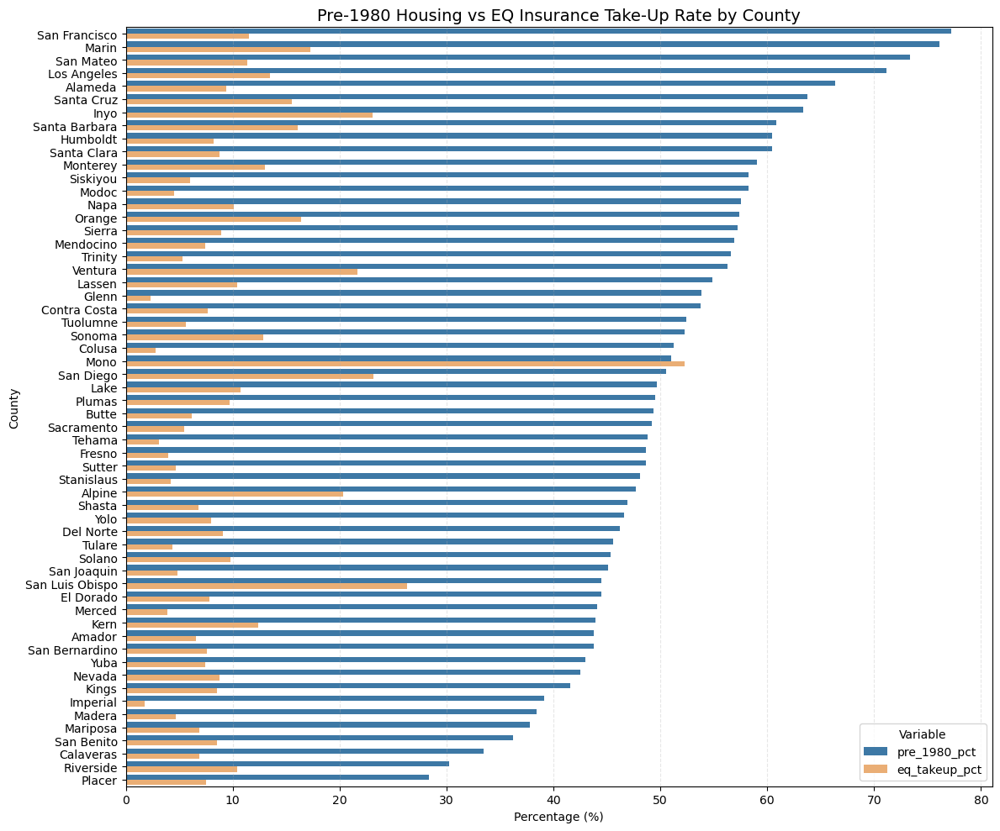

In [449]:
# Side-by-Side Barplot: Pre-1980 Housing vs EQ Take-Up
df_plot = gdf[["county", "pre_1980_pct", "eq_takeup_pct"]].copy()
df_plot = df_plot.sort_values("pre_1980_pct", ascending=False)
df_melted = df_plot.melt(id_vars="county", var_name="Variable", value_name="Value")

plt.figure(figsize=(12, 10))
sns.barplot(
    data=df_melted,
    x="Value",
    y="county",
    hue="Variable",
    palette=["#2C7BB6", "#FDAE61"]
)
plt.title("Pre-1980 Housing vs EQ Insurance Take-Up Rate by County", fontsize=14)
plt.xlabel("Percentage (%)")
plt.ylabel("County")
plt.legend(title="Variable", loc="lower right")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


> The grouped bar chart shows that many counties with **higher shares of older housing** also exhibit **higher take-up rates**.  
> - **Mono** and **San Luis Obispo** both rank high on both metrics  
> - Other counties (e.g., **Sierra**, **Alpine**) have high pre-1980 housing shares but low take-up — suggesting **other barriers**, like income or awareness, may suppress insurance uptake.
>
> Overall, this variable appears to be **moderately correlated** with take-up behavior and may help identify structurally vulnerable, underinsured regions.


In [451]:
# Preview Top 10 by EQ Take-Up
gdf[["county", "pre_1980_pct", "eq_takeup_pct"]].sort_values("eq_takeup_pct", ascending=False).head(10)


,county,pre_1980_pct,eq_takeup_pct
20,Mono,51.02,52.3
57,San Luis Obispo,44.47,26.3
8,San Diego,50.58,23.2
19,Inyo,63.35,23.1
4,Ventura,56.30,21.7
25,Alpine,47.70,20.3
11,Marin,76.11,17.3
47,Orange,57.38,16.4
2,Santa Barbara,60.82,16.1
55,Santa Cruz,63.74,15.5


---
#### ➤ ✅ Conclusion  
- `pre_1980_pct` offers more analytical value than the raw count  
- Moderate correlation with insurance take-up — especially when outliers like Mono are excluded  
- A useful variable for modeling underinsurance and seismic vulnerability


---

### 🧬 Investigation of Skewed Variable — `american_indian_alone_pct`

In this section, I explored the relationship between the percentage of residents identifying as American Indian (alone) and earthquake insurance take-up rates. While this population represents a small share in most counties, certain rural areas in Northern and Eastern California have significantly higher proportions.

---

### 🧑‍🦲 American Indian Population (%)  
- Scatterplot with annotations  
- Binned analysis and grouped means  
- Pearson & Spearman correlation  
- ✅ *Conclusion: Weak-to-moderate pattern; high variance*

---
#### ➤ Visual Patterns and Key Counties


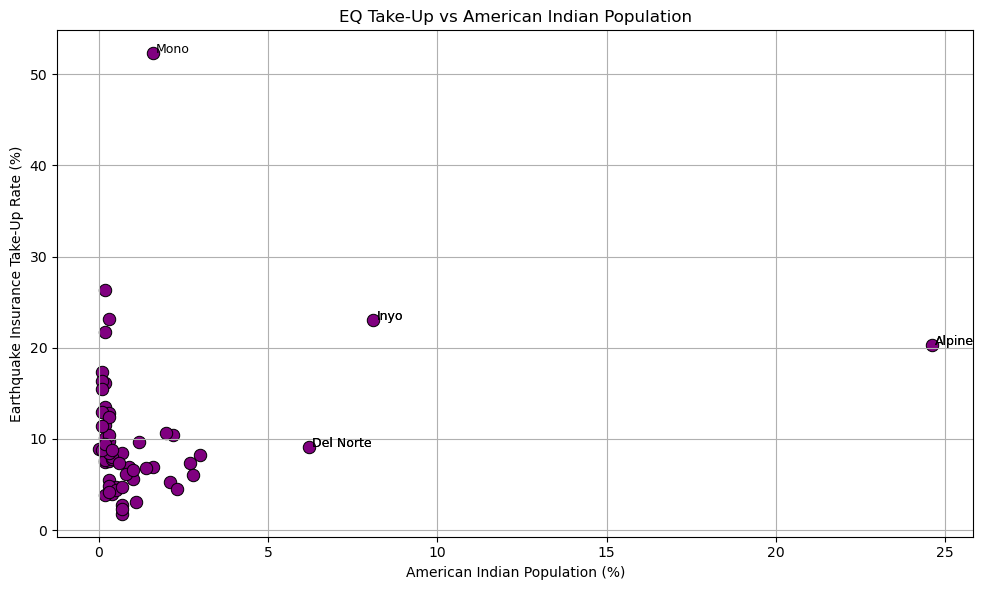

In [454]:
# Scatter Plot: American Indian % vs EQ Take-Up %
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=gdf,
    x="american_indian_alone_pct",
    y="eq_takeup_pct",
    s=80,
    color="purple",
    edgecolor="black"
)

# Annotate counties with high American Indian population
high_native = gdf[gdf["american_indian_alone_pct"] > 5]
for _, row in high_native.iterrows():
    plt.text(
        row["american_indian_alone_pct"] + 0.1,
        row["eq_takeup_pct"],
        row["county"],
        fontsize=9
    )

# Manually highlight notable counties
highlight = ["Mono", "Alpine", "Inyo", "Del Norte"]
for _, row in gdf[gdf["county"].isin(highlight)].iterrows():
    plt.text(
        row["american_indian_alone_pct"] + 0.1,
        row["eq_takeup_pct"],
        row["county"],
        fontsize=9,
        color="black"
    )

# Formatting
plt.xlabel("American Indian Population (%)")
plt.ylabel("Earthquake Insurance Take-Up Rate (%)")
plt.title("EQ Take-Up vs American Indian Population")
plt.grid(True)
plt.tight_layout()
plt.show()


> The scatterplot revealed that:
> - Most counties have **less than 3%** American Indian population
> - A few counties stand out, including:
>   - **Alpine** (24.6%)
>   - **Inyo** (8.1%)
>   - **Del Norte** (6.2%)
>
> These counties show **moderate to high take-up rates**, but overall, there’s **no strong visual trend** across the full dataset.
> 
> **Mono County** remains an outlier with **52.3% take-up** but only **1.2% American Indian population**, indicating that other factors are likely driving its behavior.


---
#### ➤ Top Counties by American Indian Population Share


In [457]:
# Sort and display counties with highest American Indian %
gdf[["county", "american_indian_alone_pct"]].sort_values(by="american_indian_alone_pct", ascending=False).head()


,county,american_indian_alone_pct
25,Alpine,24.6
19,Inyo,8.1
34,Del Norte,6.2
30,Humboldt,3.0
54,Siskiyou,2.8


> Counties with the highest percentages of American Indian residents tend to be **rural and geographically isolated**, such as Alpine, Inyo, and Del Norte.  
> These areas may have distinct housing, risk perception, or tribal insurance considerations not captured in statewide models.

---
#### ➤ Correlation Analysis


In [459]:
# Pearson (linear) and Spearman (rank) correlation
pearson_corr, _ = pearsonr(gdf["american_indian_alone_pct"], gdf["eq_takeup_pct"])
spearman_corr, _ = spearmanr(gdf["american_indian_alone_pct"], gdf["eq_takeup_pct"])

print(f"Pearson correlation: {pearson_corr:.2f}")
print(f"Spearman correlation: {spearman_corr:.2f}")


Pearson correlation: 0.20
Spearman correlation: -0.31


> To quantify the relationship:
> - **Pearson correlation** (linear): **0.20**
> - **Spearman correlation** (rank-based): **-0.31**
>
> This suggests a **conflicting picture**:
> - The linear trend is slightly positive, driven by a few counties with both higher Native population and higher take-up
> - However, the **negative Spearman correlation** implies that higher Native population **does not consistently correspond** with higher take-up when ranked — likely due to wide variability

---
#### ➤ Binned Analysis: Take-Up by American Indian %


In [461]:
# Bin counties by American Indian %
bins = [0, 1, 3, 10, 25]
labels = ["<1%", "1–3%", "3–10%", "10–25%"]
gdf["native_pct_bin"] = pd.cut(gdf["american_indian_alone_pct"], bins=bins, labels=labels)

# Compute grouped summary statistics
summary = (
    gdf.groupby("native_pct_bin", observed=False)["eq_takeup_pct"]
    .agg(["count", "mean", "std"])
    .reset_index()
    .rename(columns={
        "native_pct_bin": "American Indian % Bin",
        "count": "Counties",
        "mean": "Avg Take-Up %",
        "std": "Std Dev"
    })
)

# Display summary as styled table
summary.style.format({"Avg Take-Up %": "{:.1f}", "Std Dev": "{:.1f}"})


,American Indian % Bin,Counties,Avg Take-Up %,Std Dev
0,<1%,42,9.5,5.6
1,1–3%,12,10.9,13.2
2,3–10%,2,16.1,9.9
3,10–25%,1,20.3,nan


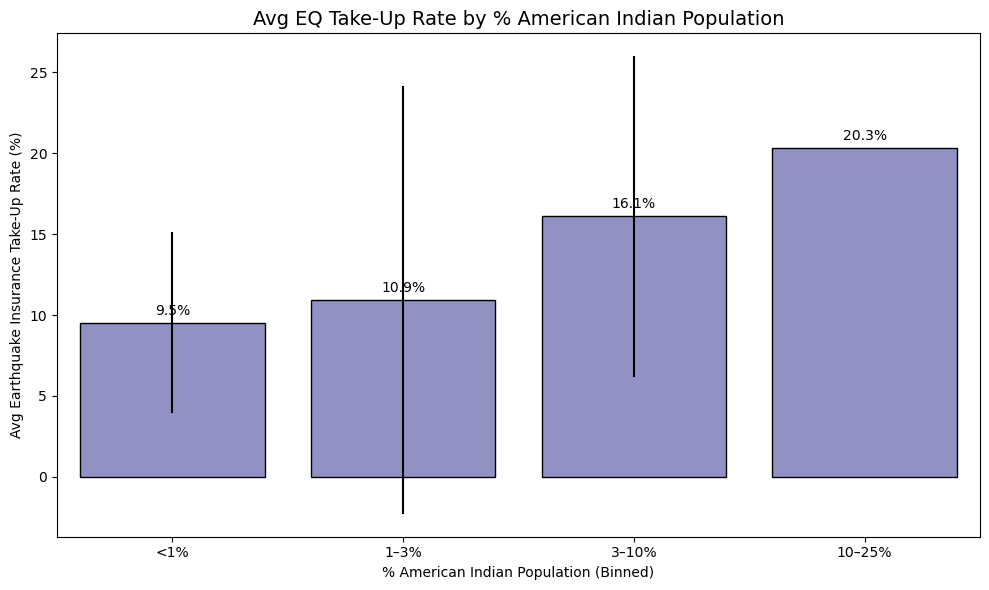

In [462]:
# Barplot with error bars for standard deviation
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=summary,
    x="American Indian % Bin",
    y="Avg Take-Up %",
    yerr=summary["Std Dev"],
    color="#88c",
    edgecolor="black"
)

# Annotate bars with exact mean values
for i, row in summary.iterrows():
    ax.text(i, row["Avg Take-Up %"] + 0.5, f"{row['Avg Take-Up %']:.1f}%", ha="center", fontsize=10)

# Formatting
plt.title("Avg EQ Take-Up Rate by % American Indian Population", fontsize=14)
plt.xlabel("% American Indian Population (Binned)")
plt.ylabel("Avg Earthquake Insurance Take-Up Rate (%)")
plt.tight_layout()
plt.show()


> I grouped counties into bins based on their American Indian population percentage:
> - **<1%**
> - **1–3%**
> - **3–10%**
> - **10–25%**
>
> The grouped bar chart showed a **general upward trend** — bins with higher Native American percentages tended to have higher average take-up rates.
>
> However, **standard deviations were large** in each group, which suggests:
> - There’s **high within-group variability**
> - The observed trend is **not consistent** and may be driven by a small number of influential counties


---
#### ➤ ✅ Conclusion
- The variable `american_indian_alone_pct` shows **some positive association** with EQ insurance take-up, but the relationship is **weak and noisy**
- Results are **sensitive to outliers**, and the overall trend is not consistent across bins or ranks
- I may consider **interacting this variable with others** (e.g., rural status, housing age) in future models to better understand its impact

---
### ✅ Summary – Part 1: Dataset Overview & Initial Exploration

In the first phase of my exploratory analysis, I focused on understanding the **spread and skewness** of key variables in the dataset — particularly those related to housing stock, demographics, seismic risk, and disaster history.

Several variables showed **extremely high variance**, especially raw count variables such as `fema_funding_earthquake`, `built_pre_1980`, and `total_population`.  
This is expected due to the **large differences in county size** — with urban areas like Los Angeles dwarfing rural counties like Alpine or Sierra.

To address this imbalance and enable **more meaningful comparisons across counties**, I derived and shifted focus toward **percentage-based or normalized variables**, including:

- `pre_1980_pct` – % of housing built before 1980  
- `american_indian_alone_pct` – % identifying as American Indian (alone)  
- `below_poverty_pct` – % of population living below poverty line  
- `eq_takeup_pct` – % of residential units with earthquake insurance  

These variables offer a **relative, size-independent view** of housing vulnerability, demographic sensitivity, and insurance behavior.

This foundation will support deeper, theme-specific exploration in **Part 2**, where I group variables by topic (e.g., demographics, housing, risk exposure) and analyze their relationships with earthquake insurance take-up rates.


---
## 📊 Part 2 – Thematic EDA by Variable Group

___

### 📊 Percentage-Based Variables

To ensure fair comparisons across counties of different population sizes, we prioritize percentage-based variables in our exploratory analysis. These include:

- **Demographics:** Age, Race, Ethnicity
- **Housing Tenure:** Owner/Renter distribution, Pre-1980 housing
- **Insurance & Poverty:** Earthquake take-up rate, Loss ratios, Homeowners coverage, Poverty levels
- **Vacancy Characteristics:** Various categories of housing vacancy


In [465]:
# Find all columns that include 'pct' in their name
pct_columns = [col for col in gdf.columns if 'pct' in col.lower()]

# Display the list
print("Percentage-based variables in the dataset:")
for col in pct_columns:
    print(f"• {col}")

Percentage-based variables in the dataset:
• age_0_17_pct
• age_18_64_pct
• age_65_up_pct
• below_poverty_pct
• white_alone_pct
• black_alone_pct
• american_indian_alone_pct
• asian_alone_pct
• native_hawaiian_alone_pct
• hispanic_pct
• owner_pct
• renter_pct
• for_rent_pct
• rented_not_occupied_pct
• for_sale_pct
• sold_not_occupied_pct
• seasonal_pct
• migrant_pct
• other_vacant_pct
• eq_takeup_pct
• modeled_loss_ratio_2018_pct
• homeowners_coverage_pct
• pre_1980_pct
• native_pct_bin


---
### Group 1: Age Distribution

In this section, I analyzed the age composition of each California county and its potential relationship to earthquake insurance behavior.

I focused on three main variables:
- `age_0_17_pct` – share of the population under 18
- `age_65_up_pct` – share of the population aged 65 and older
- `senior_minus_youth` – the difference between seniors and youth


In [467]:
# Select age variables
age_cols = ["age_0_17_pct", "age_18_64_pct", "age_65_up_pct"]
gdf[age_cols].describe().T.style.format("{:,.2f}")


,count,mean,std,min,25%,50%,75%,max
age_0_17_pct,58.00,21.85,4.04,12.80,19.23,21.10,25.48,30.10
age_18_64_pct,58.00,59.18,4.00,49.80,56.92,59.55,61.70,69.10
age_65_up_pct,58.00,18.97,5.91,10.60,14.55,16.90,22.55,34.50


> **Quick Observations – Age Composition**
> - Most counties are **majority working-age (18–64)**, with an average of **~59%**
> - The **child population** (`age_0_17_pct`) ranges from **~13% to 30%**
> - The **senior population** (`age_65_up_pct`) has a wider spread — from **~10% to 34.5%**
>
> While the range is meaningful, age group percentages show **relatively moderate spread** compared to high-variance variables like population or FEMA funding. These normalized values are **well-suited for cross-county comparison**, especially in the context of behavioral modeling.

---
#### ➤ Age Group Distribution by County (Stacked View)
Stacked barplot showing the composition of age groups across California counties.


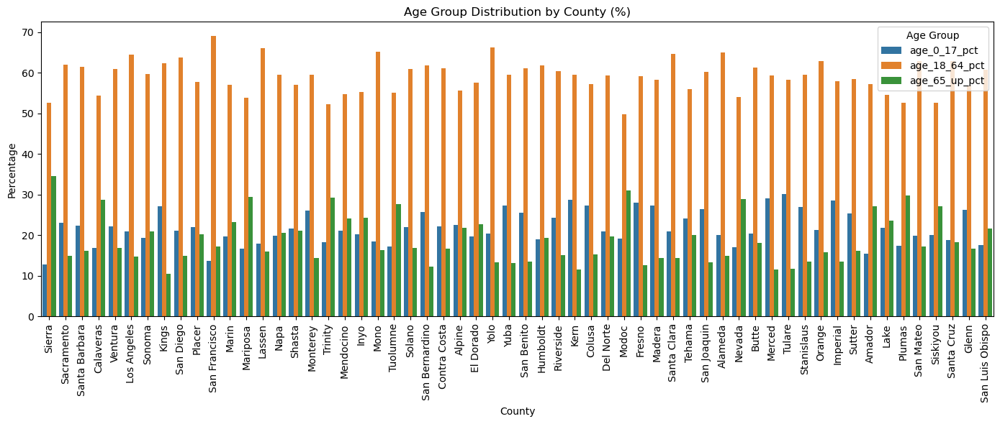

In [469]:
age_df = gdf[["county"] + age_cols].copy()
age_long = age_df.melt(id_vars="county", var_name="age_group", value_name="percentage")

plt.figure(figsize=(14, 6))
sns.barplot(data=age_long, x="county", y="percentage", hue="age_group")
plt.title("Age Group Distribution by County (%)")
plt.ylabel("Percentage")
plt.xlabel("County")
plt.xticks(rotation=90)
plt.legend(title="Age Group")
plt.tight_layout()
plt.show()


> **Key Takeaways from the Age Distribution Plot**
> - **Majority Age Group**:  
>   In every county, the largest age group is **18–64 years**, representing the working-age population. Most counties fall between **55–65%** in this category.
> - **Youth vs. Seniors**:  
>   In most counties, the share of **children (0–17)** exceeds that of **seniors (65+)**.  
>   However, a few rural or retirement-oriented counties — such as **Sierra**, **Mariposa**, and **Amador** — have a **higher percentage of seniors than youth**.
> - **Implications for Earthquake Insurance**:  
>   Older populations may be **more risk-aware**, potentially leading to **higher insurance interest**, but they may also face **affordability barriers**, especially in fixed-income households.  
>   Counties with more youth may reflect **family-oriented populations** or **new homeowners**, which could influence insurance adoption differently.


---
#### ➤ Correlation with EQ Take-Up Rate
Pearson and Spearman correlations between age group percentages and earthquake insurance take-up rate.


In [472]:
# Select variables
age_vars = ["age_0_17_pct", "age_18_64_pct", "age_65_up_pct"]

# Compute correlations
for var in age_vars:
    pearson_corr, _ = pearsonr(gdf[var], gdf["eq_takeup_pct"])
    spearman_corr, _ = spearmanr(gdf[var], gdf["eq_takeup_pct"])
    print(f"📊 {var}")
    print(f"   • Pearson  : {pearson_corr:.2f}")
    print(f"   • Spearman : {spearman_corr:.2f}\n")


📊 age_0_17_pct
   • Pearson  : -0.29
   • Spearman : -0.36

📊 age_18_64_pct
   • Pearson  : 0.32
   • Spearman : 0.40

📊 age_65_up_pct
   • Pearson  : -0.01
   • Spearman : 0.13



> **Age Demographics and Earthquake Insurance Take-Up**
> - **Youth (0–17 years)**:  
>   Shows a **moderate negative correlation** with take-up. This may reflect **lower perceived risk** or **budget limitations** among families with children.
> - **Working-Age Adults (18–64 years)**:  
>   Displays the **strongest positive correlation** with take-up. Likely related to **homeownership**, **income stability**, and **asset protection behavior**.
> - **Seniors (65+ years)**:  
>   Shows **very weak or no linear correlation**. Suggests mixed take-up behavior — possibly influenced by fixed income, home equity, or regional factors.
>
> These results support the idea that **insurance awareness and affordability interventions** may be especially important in **younger, family-oriented counties**, where take-up rates are currently lower.

---
#### ➤ Identify Counties Where Seniors Outnumber Youth
Flag counties where the senior population percentage exceeds that of youth, indicating potential age-skewed demographics.


In [474]:
# Filter counties where seniors outnumber youth
gdf["senior_minus_youth"] = gdf["age_65_up_pct"] - gdf["age_0_17_pct"]
gdf["seniors_gt_youth"] = gdf["senior_minus_youth"] > 0

senior_dominant = gdf[gdf["seniors_gt_youth"]].copy()
senior_dominant = senior_dominant.sort_values("eq_takeup_pct", ascending=False)

# Preview
print("Counties where seniors (65+) outnumber youth (0–17):")
display(senior_dominant[["county", "age_65_up_pct", "age_0_17_pct", "senior_minus_youth", "eq_takeup_pct"]])


Counties where seniors (65+) outnumber youth (0–17):


,county,age_65_up_pct,age_0_17_pct,senior_minus_youth,eq_takeup_pct
57,San Luis Obispo,21.6,17.6,4.0,26.3
19,Inyo,24.4,20.3,4.1,23.1
11,Marin,23.3,19.7,3.6,17.3
6,Sonoma,21.0,19.3,1.7,12.9
10,San Francisco,17.2,13.7,3.5,11.5
51,Lake,23.6,21.8,1.8,10.7
14,Napa,20.6,19.9,0.7,10.1
52,Plumas,29.8,17.5,12.3,9.7
0,Sierra,34.5,12.8,21.7,8.9
42,Nevada,28.9,17.1,11.8,8.8


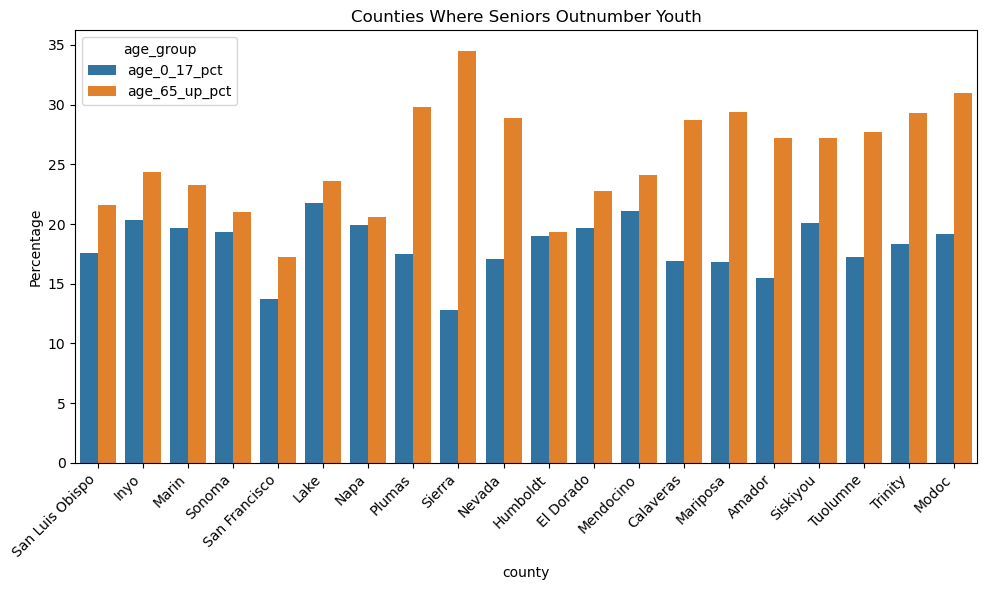

In [475]:
# Barplot to compare youth vs. senior % in those counties
plt.figure(figsize=(10, 6))
df_melt = senior_dominant.melt(
    id_vars="county",
    value_vars=["age_0_17_pct", "age_65_up_pct"],
    var_name="age_group",
    value_name="percentage"
)

sns.barplot(
    data=df_melt,
    x="county",
    y="percentage",
    hue="age_group"
)
plt.title("Counties Where Seniors Outnumber Youth")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Percentage")
plt.tight_layout()
plt.show()


> **Aging Population: Counties Where Seniors Outnumber Youth**  
> In 19 California counties, the percentage of residents aged 65 and older exceeds the share of those aged 0–17.    
> This pattern is most common in rural or retirement-oriented areas, which often experience lower birth rates and youth out-migration.
>
> **Top counties by senior dominance**:
> - **Sierra**: 34.5% seniors vs. 12.8% youth  
> - **Modoc**: 31.0% vs. 19.2%  
> - **Plumas**: 29.8% vs. 17.5%  
> - **Mariposa**: 29.4% vs. 16.8%  
> - **Trinity**: 29.3% vs. 18.3%
>
> These counties may require targeted consideration when evaluating:
> - **Earthquake preparedness for older populations**
> - **Insurance engagement strategies**, as older homeowners may be **more risk-averse**
> - **Aging infrastructure** and the capacity to withstand seismic events
>
> This demographic signal could be especially important when combined with housing age, income, or rural isolation in later modeling.

---
#### ➤ EQ Take-Up Rate in Senior-Dominant Counties
Compare earthquake insurance participation in counties with higher senior populations versus others.


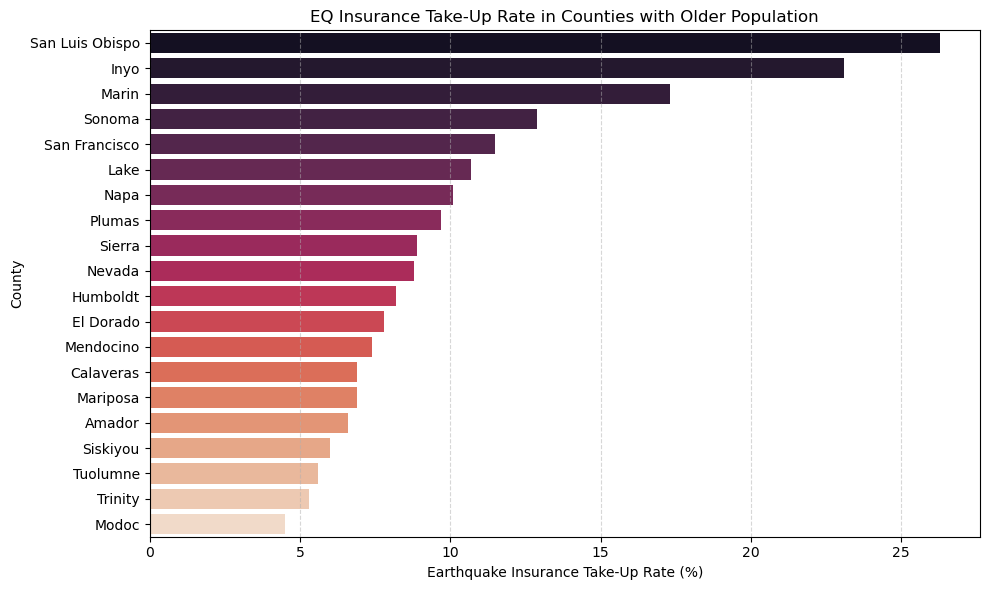

In [477]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=senior_dominant,
    x="eq_takeup_pct",
    y="county",
    hue="county",
    palette="rocket"
)
plt.title("EQ Insurance Take-Up Rate in Counties with Older Population")
plt.xlabel("Earthquake Insurance Take-Up Rate (%)")
plt.ylabel("County")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()



> **EQ Take-Up in Senior-Dominant Counties**
> - The highest take-up rates among these counties are found in **San Luis Obispo (26.3%)** and **Inyo (23.1%)**, both of which are known for active fault proximity and heightened seismic awareness.
> - Other senior-heavy counties, such as **Sierra**, **Plumas**, and **Tuolumne**, show **take-up rates below 10%**, despite having large elderly populations.  
>
>**Insight**:  
> An older population alone doesn’t guarantee higher insurance participation.  
> Take-up rates in these counties likely reflect a **mix of factors** — including:  
> - Proximity to seismic risk  
> - Insurance affordability
> - Local policy incentives or outreach
>
> This supports the idea that **age needs to be interpreted in context** — especially when used as a predictive signal.


---
#### ➤ Correlation: Senior Minus Youth % vs EQ Take-Up
Test relationship between the magnitude of the senior-youth gap and earthquake insurance take-up rate.


Pearson correlation: 0.12
Spearman correlation: 0.25


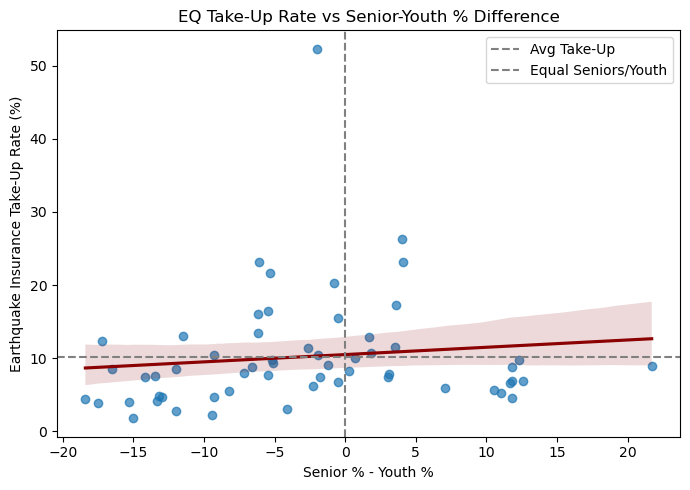

In [479]:
# Pearson and Spearman correlation
pearson_corr = gdf["senior_minus_youth"].corr(gdf["eq_takeup_pct"], method="pearson")
spearman_corr = gdf["senior_minus_youth"].corr(gdf["eq_takeup_pct"], method="spearman")

print(f"Pearson correlation: {pearson_corr:.2f}")
print(f"Spearman correlation: {spearman_corr:.2f}")

# Visualize
plt.figure(figsize=(7, 5))
sns.regplot(
    data=gdf,
    x="senior_minus_youth",
    y="eq_takeup_pct",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "darkred"},
)
plt.axhline(y=gdf["eq_takeup_pct"].mean(), linestyle="--", color="gray", label="Avg Take-Up")
plt.axvline(x=0, linestyle="--", color="gray", label="Equal Seniors/Youth")
plt.title("EQ Take-Up Rate vs Senior-Youth % Difference")
plt.xlabel("Senior % - Youth %")
plt.ylabel("Earthquake Insurance Take-Up Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()


> **Correlation: EQ Take-Up vs Senior–Youth % Difference**  
> I created a derived variable `senior_minus_youth`, representing the percentage point difference between the senior (65+) and youth (0–17) populations in each county.
>
> The scatterplot shows a **subtle upward trend**, suggesting that counties with more seniors than youth may exhibit slightly higher earthquake insurance take-up rates.
>
> - **Pearson correlation**: **0.12** → weak linear relationship  
> - **Spearman correlation**: **0.25** → slightly stronger rank-based trend
>
> While the correlations are not strong, they indicate a **potential directional signal**:  
> Counties with aging populations may be **modestly more likely** to invest in earthquake coverage — possibly due to **risk awareness**, **homeownership stability**, or **life-stage factors**.
>
> However, the relationship is far from definitive. Age dynamics should be considered **in combination with other variables** such as income, housing stock, and fault line proximity.

---
#### ➤ Focus on Counties with Senior-Youth Gap > 5%
Highlight counties where seniors outnumber youth by more than 5 percentage points, and examine their EQ insurance behavior.


In [481]:
# Filter counties where the gap is significant
senior_gap = gdf[gdf["senior_minus_youth"] > 5].copy()
display(senior_gap[["county", "age_65_up_pct", "age_0_17_pct", "senior_minus_youth", "eq_takeup_pct"]])

# Correlation within this subset
pearson_gap, _ = pearsonr(senior_gap["senior_minus_youth"], senior_gap["eq_takeup_pct"])
spearman_gap, _ = spearmanr(senior_gap["senior_minus_youth"], senior_gap["eq_takeup_pct"])

print(f"Pearson correlation (gap > 5%): {pearson_gap:.2f}")
print(f"Spearman correlation (gap > 5%): {spearman_gap:.2f}")


,county,age_65_up_pct,age_0_17_pct,senior_minus_youth,eq_takeup_pct
0,Sierra,34.5,12.8,21.7,8.9
3,Calaveras,28.7,16.9,11.8,6.9
12,Mariposa,29.4,16.8,12.6,6.9
17,Trinity,29.3,18.3,11.0,5.3
21,Tuolumne,27.7,17.2,10.5,5.6
35,Modoc,31.0,19.2,11.8,4.5
42,Nevada,28.9,17.1,11.8,8.8
50,Amador,27.2,15.5,11.7,6.6
52,Plumas,29.8,17.5,12.3,9.7
54,Siskiyou,27.2,20.1,7.1,6.0


Pearson correlation (gap > 5%): 0.50
Spearman correlation (gap > 5%): 0.62


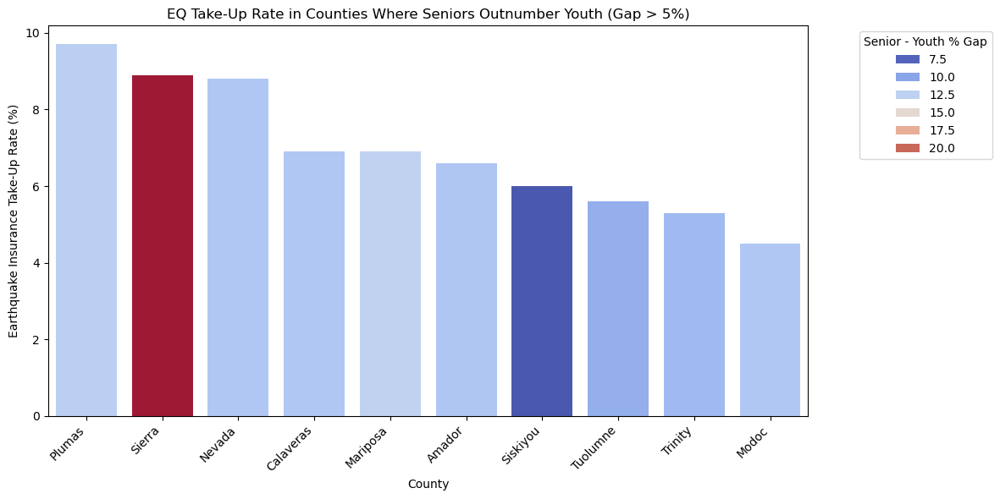

In [482]:
# Plot: Take-Up vs Senior-Youth Gap, colored by size of gap
plt.figure(figsize=(12, 6))
sns.barplot(
    data=senior_gap.sort_values("eq_takeup_pct", ascending=False),
    x="county",
    y="eq_takeup_pct",
    hue="senior_minus_youth",
    dodge=False,
    palette="coolwarm"
)
plt.title("EQ Take-Up Rate in Counties Where Seniors Outnumber Youth (Gap > 5%)")
plt.ylabel("Earthquake Insurance Take-Up Rate (%)")
plt.xlabel("County")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Senior - Youth % Gap", loc="upper right", bbox_to_anchor=(1.25, 1))
plt.tight_layout()
plt.show()


> **Seniors vs. Youth: Age Gap and EQ Insurance Take-Up**  
> I filtered the dataset to include only counties where the senior population (65+) exceeds the youth population (0–17) by more than 5 percentage points.
> In this subset of 10 counties, I examined whether the size of the senior–youth gap correlates with earthquake insurance behavior.
>
> **Correlation Results (gap > 5%)**:
> - **Pearson**: 0.50 → moderate positive linear relationship
> - **Spearman**: 0.62 → strong monotonic relationship  
>
> These results suggest that in counties with a **significantly older population profile**, earthquake insurance take-up tends to **increase as the age gap widens**.  
> This may reflect:
> - Greater **risk awareness**
> - More **financial stability** among older homeowners
> - An **asset protection mindset** among retirees
>
> However, a closer look reveals an interesting nuance:
> - Counties like **San Luis Obispo** and **Inyo**, which have only a **moderate senior-youth gap (~4%)**, show some of the **highest take-up rates** (26.3% and 23.1%).
> - By contrast, counties with the **widest age gaps** — such as **Sierra**, **Modoc**, and **Trinity** — exhibit **lower take-up rates**, despite having older populations.
>
> **Insight**:  
> While a larger senior population *can* be associated with higher take-up, it is **not the only factor**.  
> In fact, a **balanced age structure** may be more predictive of strong insurance participation than extreme senior dominance.
>
> Further investigation is needed to understand how **age composition interacts with income, housing type, seismic risk**, and **insurance affordability** in driving take-up decisions.


----
#### ✅ Conclusion – Age Composition & Insurance Behavior

- Counties where **seniors outnumber youth** tend to show **slightly higher earthquake insurance take-up rates**, possibly due to greater **risk aversion**, higher **homeownership**, or an **asset protection mindset**
- However, the **correlation is modest**, and several senior-heavy counties remain underinsured
- A **balanced age structure** may be more predictive of higher take-up than extreme age skew
- Age-based signals should be **interpreted in context** — and may gain predictive power when combined with other variables like **housing age**, **income**, or **tenure (owner vs. renter)** in future modeling

---
### 🌎 Group 2: Race & Ethnicity

In this section, I explored the racial and ethnic composition of each county and evaluated how these demographic factors relate to earthquake insurance take-up rates.

I focused on six variables:

- `white_alone_pct`  
- `hispanic_pct`  
- `asian_alone_pct`  
- `black_alone_pct`  
- `american_indian_alone_pct` (analyzed in detail earlier)  
- `native_hawaiian_alone_pct`

---
#### ➤ Review Summary Stats
Descriptive statistics of racial and ethnic group percentages by county.

In [484]:
race_ethnicity_cols = [
    "white_alone_pct", "black_alone_pct", "american_indian_alone_pct", 
    "asian_alone_pct", "native_hawaiian_alone_pct", "hispanic_pct"
]

gdf[race_ethnicity_cols].describe().T.sort_values("mean", ascending=False)


,count,mean,std,min,25%,50%,75%,max
white_alone_pct,58.0,50.725862,19.935964,9.4,31.55,49.0,66.600,88.8
hispanic_pct,58.0,32.170690,18.393220,5.9,15.60,27.1,46.725,85.6
asian_alone_pct,58.0,7.753448,9.008752,0.0,1.90,4.4,8.650,39.3
black_alone_pct,58.0,2.810345,2.758826,0.0,0.95,1.7,3.350,12.6
american_indian_alone_pct,58.0,1.360345,3.410610,0.0,0.20,0.4,1.075,24.6
native_hawaiian_alone_pct,58.0,0.291379,0.261094,0.0,0.10,0.2,0.400,1.1


>- **White Alone %**  
>  Most counties have majority White population (median ~49%). Spread is wide—from 9.4% to 88.8%.  
>- **Hispanic %**  
>  High variation across counties (from 5.9% to 85.6%). Median is 27.1%—shows some counties are majority Hispanic.  
>- **Asian Alone %**  
>  Mean is ~7.8%, but skewed by a few counties (e.g. Santa Clara, SF). Many have low single-digit values.  
>- **Black Alone %**  
>  Generally low percentages (mean ~2.8%), max is 12.6%.  
>- **American Indian Alone %**  
>  Mostly very small values, but a few outliers (Alpine, Inyo, Del Norte). Already analyzed.  
>- **Native Hawaiian / Pacific Islander %**  
>  Very low across the board. Likely not a strong variable unless binned or aggregated.   

---
#### ➤ Barplot: Race/Ethnicity Percentages by County
Visual comparison of White, Hispanic, and Asian population shares across all counties.


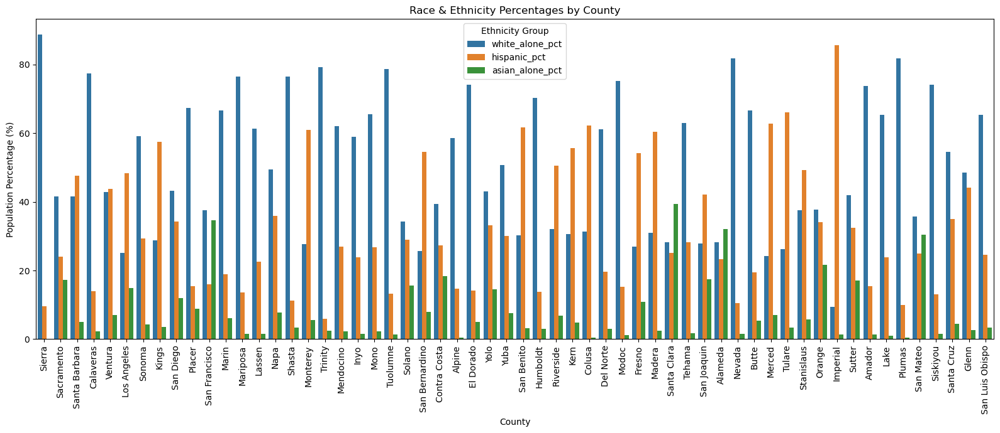

In [486]:
# Select relevant columns
ethnicity_cols = ["county", "white_alone_pct", "hispanic_pct", "asian_alone_pct"]
df_plot = gdf[ethnicity_cols].copy()

# Melt into long format
df_melted = df_plot.melt(id_vars="county", var_name="Ethnicity", value_name="Percentage")

# Plot
plt.figure(figsize=(16, 7))
sns.barplot(
    data=df_melted,
    x="county",
    y="Percentage",
    hue="Ethnicity"
)

plt.title("Race & Ethnicity Percentages by County")
plt.xticks(rotation=90, ha='center')
plt.ylabel("Population Percentage (%)")
plt.xlabel("County")
plt.legend(title="Ethnicity Group")
plt.tight_layout()
plt.show()


> **Quick Observation – Race & Ethnicity by County**  
> The chart highlights significant variation across counties:
> - Some counties are **majority White**, while others are **majority Hispanic** (e.g., Imperial, Tulare)
> - **Asian populations** are concentrated in a few counties (e.g., San Francisco, Santa Clara)
>
> This distribution reflects California’s diverse demographic landscape — which may influence housing, insurance behavior, and risk perception differently across regions.

---
#### ➤ Correlation Race & Ethnicity with `eq_takeup_pct`
Measured Pearson and Spearman correlations between racial composition and earthquake insurance participation.


In [488]:
for col in [
     "white_alone_pct", "black_alone_pct", "american_indian_alone_pct",
     "asian_alone_pct", "native_hawaiian_alone_pct", "hispanic_pct"
]:
    pearson_corr = gdf[col].corr(gdf["eq_takeup_pct"], method="pearson")
    spearman_corr = gdf[col].corr(gdf["eq_takeup_pct"], method="spearman")
    print(f"📊 {col}")
    print(f"   • Pearson  : {pearson_corr:.2f}")
    print(f"   • Spearman : {spearman_corr:.2f}\n")


📊 white_alone_pct
   • Pearson  : 0.11
   • Spearman : 0.05

📊 black_alone_pct
   • Pearson  : -0.13
   • Spearman : -0.02

📊 american_indian_alone_pct
   • Pearson  : 0.20
   • Spearman : -0.31

📊 asian_alone_pct
   • Pearson  : -0.01
   • Spearman : 0.16

📊 native_hawaiian_alone_pct
   • Pearson  : -0.03
   • Spearman : 0.15

📊 hispanic_pct
   • Pearson  : -0.13
   • Spearman : -0.10



> **Correlation: Race & Ethnicity vs EQ Insurance Take-Up**  
> I computed Pearson and Spearman correlations between race/ethnicity variables and earthquake insurance take-up rates.  
> The results show **no strong linear or monotonic relationships** for most groups:
>
> - **White Alone %**: weak positive (Pearson: 0.11)  
> - **Black Alone %**: weak negative (Pearson: -0.13)  
> - **Hispanic %**: weak negative (Pearson: -0.13)  
> - **Asian %**: essentially no correlation (Pearson: -0.01)
> - **Native Hawaiian %**: no meaningful relationship  
> - **American Indian Alone %**: previously explored — shows conflicting signals due to outliers (Pearson: 0.20, Spearman: -0.31)
>
> **Takeaway**:  
> Race and ethnicity variables **alone** do not strongly explain differences in insurance take-up across counties.  
> It's likely that **structural factors** — such as **housing type**, **ownership rates**, **building age**, and **socioeconomic conditions** — play a more direct role, and may interact with race/ethnicity in complex ways.

---
#### ➤ Correlation Race Groups with `owner_pct` and `renter_pct`
Explores how each racial group relates to homeownership vs renting — an important indirect factor in EQ insurance behavior.


In [490]:
# Define variable groups
race_cols = [
    "white_alone_pct", "black_alone_pct", "asian_alone_pct",
    "hispanic_pct", "native_hawaiian_alone_pct", "american_indian_alone_pct"
]
occupancy_cols = ["owner_pct", "renter_pct"]

# Compute correlations
results = []

for race_col in race_cols:
    for occ_col in occupancy_cols:
        pearson_corr, _ = pearsonr(gdf[race_col], gdf[occ_col])
        spearman_corr, _ = spearmanr(gdf[race_col], gdf[occ_col])
        results.append({
            "Race Group": race_col,
            "Occupancy": occ_col,
            "Pearson": round(pearson_corr, 2),
            "Spearman": round(spearman_corr, 2)
        })

# Convert to DataFrame for display
correlation_df = pd.DataFrame(results)
correlation_df


,Race Group,Occupancy,Pearson,Spearman
0,white_alone_pct,owner_pct,0.70,0.71
1,white_alone_pct,renter_pct,-0.70,-0.71
2,black_alone_pct,owner_pct,-0.36,-0.47
3,black_alone_pct,renter_pct,0.36,0.47
4,asian_alone_pct,owner_pct,-0.56,-0.63
5,asian_alone_pct,renter_pct,0.56,0.63
6,hispanic_pct,owner_pct,-0.50,-0.59
7,hispanic_pct,renter_pct,0.50,0.59
8,native_hawaiian_alone_pct,owner_pct,-0.21,-0.27
9,native_hawaiian_alone_pct,renter_pct,0.21,0.27


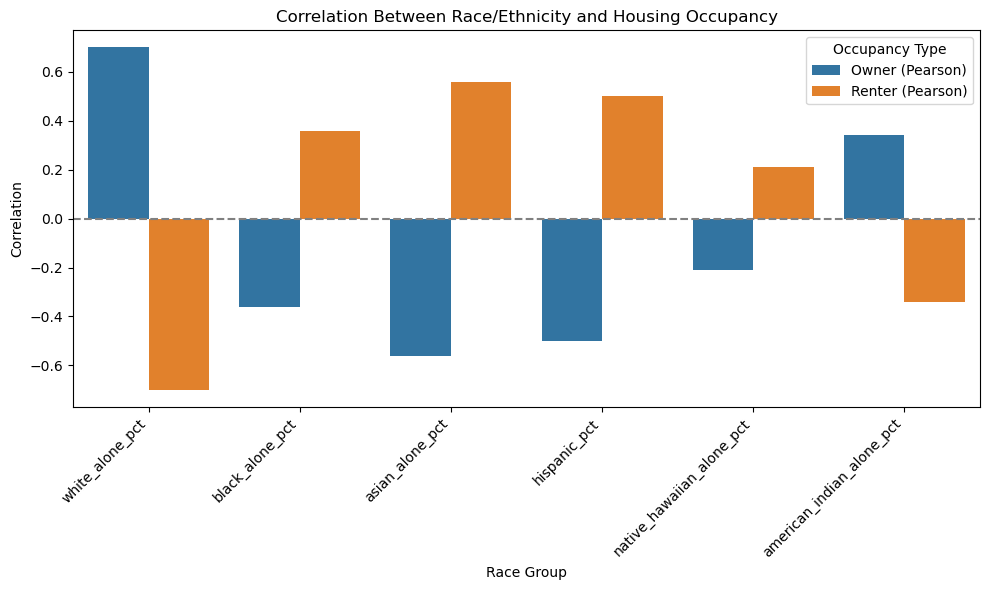

In [491]:
# Correlation results
data = {
    "Race Group": [
        "white_alone_pct", "black_alone_pct", "asian_alone_pct", "hispanic_pct",
        "native_hawaiian_alone_pct", "american_indian_alone_pct"
    ],
    "Owner (Pearson)": [0.70, -0.36, -0.56, -0.50, -0.21, 0.34],
    "Renter (Pearson)": [-0.70, 0.36, 0.56, 0.50, 0.21, -0.34]
}

df = pd.DataFrame(data)

# Melt to long format for grouped bar plot
df_melted = df.melt(id_vars="Race Group", 
                    value_vars=["Owner (Pearson)", "Renter (Pearson)"],
                    var_name="Occupancy Type", value_name="Correlation")

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=df_melted, x="Race Group", y="Correlation", hue="Occupancy Type")
plt.title("Correlation Between Race/Ethnicity and Housing Occupancy")
plt.xticks(rotation=45, ha="right")
plt.axhline(0, color="gray", linestyle="--")
plt.tight_layout()
plt.show()


> **Race & Ethnicity vs Housing Occupancy**  
> I examined how racial and ethnic composition correlates with **homeownership (owner_pct)** and **rentership (renter_pct)** across counties:
>
> - **White Alone %**: Strong positive correlation with homeownership (Pearson: 0.70)  
> - **Asian %**: Strong negative correlation with homeownership (Pearson: -0.56) — renter-skewed  
> - **Hispanic %**: Also renter-dominant (Pearson: -0.50 for ownership)
> - **Black %**: Moderate renter preference, but not as strong
> - **American Indian %**: The **only minority group** with a positive correlation to homeownership (Pearson: 0.34)
>
> **Takeaway**:  
> Race and ethnicity are **strongly tied to housing tenure** in California counties.    
> Since **renters tend to have lower EQ insurance take-up** (explored later), this adds a structural context for interpreting racial disparities in coverage.    
> Targeted strategies may be needed to address **renter-heavy communities**, particularly where cultural or economic factors intersect.  

---
#### ✅ Conclusion – Race & Ethnicity & Insurance Behavior  

**Race & Ethnicity appear to influence earthquake insurance behavior *indirectly*** — primarily through differences in homeownership:

 - No race or ethnicity group showed a strong direct correlation with earthquake insurance take-up.
 - However, homeownership rates vary **sharply by racial group**:
     - **White populations** are strongly associated with homeownership.
     - **Asian and Hispanic groups** are more associated with renting.
     - **American Indian populations** show a positive correlation with homeownership — a unique pattern among minorities.

 **Key Insight**: Since renters are less likely to purchase earthquake insurance, these housing tenure patterns may partially explain disparities across racial lines.

Further exploration may consider:
 - Whether racial disparities persist after controlling for income, age of housing, and insurance availability.
 - How outreach and education strategies could be adapted to **renter-heavy** or **minority-majority** communities.

---
### 💰 Group 3: Poverty & Insurance

In this section, I explored how poverty levels, homeowners insurance coverage, and modeled earthquake loss influence earthquake insurance take-up across California counties.

I focused on the following key variables:

- `below_poverty_pct` — share of county population living below the federal poverty line  
- `homeowners_coverage_pct` — percent of housing units covered by standard homeowners insurance  
- `modeled_loss_ratio_2018_pct` — estimated average annual earthquake loss as a percentage of building value  
- `eq_takeup_pct` — observed earthquake insurance participation rate  

---
#### ➤ Review Summary Stats
Provides descriptive statistics for poverty rate, homeowners coverage, modeled loss ratio, and earthquake insurance take-up — highlighting distributions and outliers. 


In [493]:
gdf[[
    "below_poverty_pct",
    "eq_takeup_pct",
    "modeled_loss_ratio_2018_pct",
    "homeowners_coverage_pct"
]].describe().T


,count,mean,std,min,25%,50%,75%,max
below_poverty_pct,58.0,12.851724,3.790303,6.5,10.425,12.60,15.375,20.3
eq_takeup_pct,58.0,10.217241,7.843695,1.8,5.700,8.35,11.475,52.3
modeled_loss_ratio_2018_pct,58.0,11.598276,3.615342,7.0,9.300,11.10,11.700,19.9
homeowners_coverage_pct,58.0,65.265517,10.865422,30.4,59.600,66.50,72.550,84.0


>**Summary Observations**    
>- **Poverty Rate (`below_poverty_pct`)** ranges from 6.5% to 20.3%, with most counties clustering around 12–13%.  
>- **Earthquake Take-Up Rate (`eq_takeup_pct`)** is heavily right-skewed — most counties fall below 15%, but a few outliers (e.g. Mono) push the max above 50%.  
>- **Modeled Loss Ratio (`modeled_loss_ratio_2018_pct`)** is tightly distributed (7%–20%) and may be a strong predictor of insurance need/risk perception.  
>- **Homeowners Insurance Coverage (`homeowners_coverage_pct`)** is generally high (median 66.5%), but varies substantially — some counties fall below 50%, indicating low insurance market penetration.
>
>This group of variables provides an important lens into both **financial capacity** and **perceived risk** — two crucial drivers of earthquake insurance participation.

---
#### ➤ Correlation with EQ Take-Up Rate
Measures how each socioeconomic variable relates to earthquake insurance take-up, using both Pearson and Spearman correlation methods.
                                                                                              

In [495]:
cols_to_check = [ 
    "below_poverty_pct", 
    "modeled_loss_ratio_2018_pct", 
    "homeowners_coverage_pct" 
] 

for col in cols_to_check: 
    pearson_corr = pearsonr(gdf[col], gdf["eq_takeup_pct"])[0] 
    spearman_corr = spearmanr(gdf[col], gdf["eq_takeup_pct"])[0] 
    print(f"📊 {col}") 
    print(f" • Pearson : {pearson_corr:.2f}") 
    print(f" • Spearman : {spearman_corr:.2f}\n")
    

📊 below_poverty_pct
 • Pearson : -0.31
 • Spearman : -0.45

📊 modeled_loss_ratio_2018_pct
 • Pearson : -0.11
 • Spearman : -0.33

📊 homeowners_coverage_pct
 • Pearson : -0.40
 • Spearman : -0.23



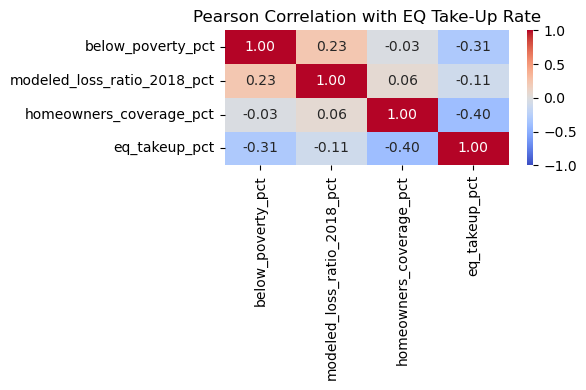

In [496]:
# Select relevant columns
cols = [
    "below_poverty_pct",
    "modeled_loss_ratio_2018_pct",
    "homeowners_coverage_pct",
    "eq_takeup_pct"
]

# Compute correlation matrix
corr_matrix = gdf[cols].corr(method='pearson')

# Plot heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1, vmax=1,
    fmt=".2f"
)
plt.title("Pearson Correlation with EQ Take-Up Rate")
plt.tight_layout()
plt.show()


>**Correlation Observations**  
>- **Poverty Rate (`below_poverty_pct`)** shows a **moderate negative correlation** with earthquake take-up:  
>  Pearson: **-0.31**, Spearman: **-0.45**  
>  Counties with higher poverty tend to have **lower insurance participation**, likely due to financial barriers.  
>
>- **Modeled Loss Ratio (`modeled_loss_ratio_2018_pct`)** has a **weak and inconsistent correlation**:    
>  Pearson: **-0.11**, Spearman: **-0.33**  
>  While this reflects risk exposure, it doesn't clearly translate into take-up behavior — possibly due to a **disconnect between modeled risk and public perception**.
>
>- **Homeowners Coverage (`homeowners_coverage_pct`)** shows the **strongest (negative) correlation** in this group:  
>  Pearson: **-0.40**, Spearman: **-0.23**  
>  Surprisingly, counties with **higher general homeowners insurance coverage** often have **lower earthquake insurance participation**.
>
>This section underscores how economic vulnerability and insurance accessibility strongly influence earthquake coverage uptake across California counties.

---
#### ➤ EQ Take-Up vs Homeowners Insurance (scatter + barplot)
Visualizes the relationship between general homeowners coverage and earthquake insurance take-up across counties — identifying patterns, gaps, and standout regions.


In [498]:
gdf[["county", "homeowners_coverage_pct", "eq_takeup_pct"]].sort_values("homeowners_coverage_pct", ascending=False).head(10) 


,county,homeowners_coverage_pct,eq_takeup_pct
3,Calaveras,84.0,6.9
13,Lassen,83.7,10.4
29,San Benito,83.4,8.5
42,Nevada,79.3,8.8
50,Amador,78.8,6.6
37,Madera,78.3,4.7
9,Placer,77.5,7.5
21,Tuolumne,76.4,5.6
26,El Dorado,76.0,7.8
15,Shasta,75.3,6.8


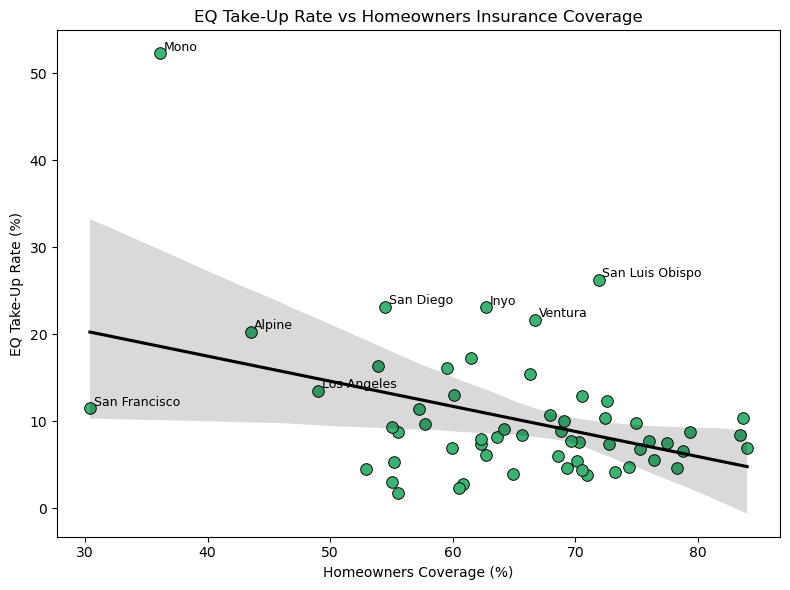

In [499]:
# Scatter Plot: Homeowners Insurance vs Earthquake Take-Up Rate

plt.figure(figsize=(8, 6))

# Scatter plot
ax = sns.scatterplot(
    data=gdf,
    x="homeowners_coverage_pct",
    y="eq_takeup_pct",
    s=70,
    color="mediumseagreen",
    edgecolor="black"
)

# Add regression line (no linestyle)
sns.regplot(
    data=gdf,
    x="homeowners_coverage_pct",
    y="eq_takeup_pct",
    scatter=False,
    ax=ax,
    color="black"
)

# Annotate a few key counties (optional logic)
for i, row in gdf.iterrows():
    if row["eq_takeup_pct"] > 20 or row["homeowners_coverage_pct"] < 50:
        ax.text(
            row["homeowners_coverage_pct"] + 0.3,
            row["eq_takeup_pct"] + 0.3,
            row["county"],
            fontsize=9
        )

# Axis labels and title
ax.set_title("EQ Take-Up Rate vs Homeowners Insurance Coverage")
ax.set_xlabel("Homeowners Coverage (%)")
ax.set_ylabel("EQ Take-Up Rate (%)")

plt.tight_layout()
plt.show()


>**Observation: Homeowners Insurance vs EQ Take-Up Rate**  
>- Contrary to expectations, this scatter plot reveals a moderate negative correlation between homeowners coverage and earthquake insurance take-up (Pearson: -0.40).  
>- Counties with higher general homeowners insurance coverage (e.g., Calaveras, Lassen, Amador) often show low EQ take-up rates, while some counties with lower coverage (e.g., Mono, San Luis Obispo, Inyo) exhibit higher take-up.  
>
>This suggests that earthquake insurance behavior is not simply a subset of general insurance uptake, and may be influenced more by perceived seismic risk, housing type, or targeted policy incentives.


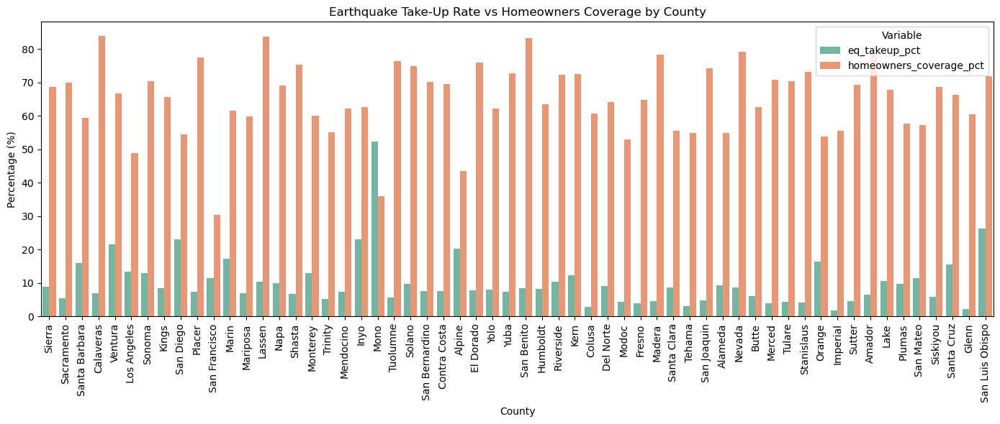

In [501]:
# Barplot: Earthquake Take-Up Rate vs Homeowners Coverage by County

melted = gdf[["county", "eq_takeup_pct", "homeowners_coverage_pct"]].melt(
    id_vars="county", var_name="variable", value_name="value"
)

plt.figure(figsize=(14, 6))
ax = sns.barplot(data=melted, x="county", y="value", hue="variable", palette="Set2")

ax.set_xticks(range(len(gdf["county"])))
ax.set_xticklabels(gdf["county"], rotation=90)

ax.set_ylabel("Percentage (%)")
ax.set_xlabel("County")
ax.set_title("Earthquake Take-Up Rate vs Homeowners Coverage by County")
plt.legend(title="Variable", loc="upper right")
plt.tight_layout()
plt.show()


> **Observation: EQ Take-Up vs Homeowners Coverage by County**  
>This side-by-side barplot highlights the disparity between general homeowners insurance coverage and earthquake insurance take-up across California counties.
>
>Most counties show substantially higher homeowners insurance coverage compared to EQ take-up rates, reinforcing the idea that earthquake insurance is treated as a separate and less common product.
>
>Counties like **Mono**, **San Luis Obispo**, and **San Diego** stand out with notably higher EQ take-up rates, while others (e.g., **Imperial**, **Glenn**, **Colusa**) exhibit very low EQ participation despite moderate homeowners coverage — signaling potential underinsurance gaps.

---
#### ✅ Conclusion – Poverty & Insurance
- **Counties with higher poverty rates tend to have lower earthquake insurance take-up**. This is more pronounced with Spearman correlation (–0.45), indicating a consistent rank-order trend.
- **Homeowners insurance coverage shows a moderate negative correlation** with EQ take-up (Pearson –0.40), possibly reflecting broader patterns of insurance adoption or access.
- **Modeled loss ratio** has a weak correlation with EQ take-up, suggesting that expected earthquake risk alone does not strongly drive insurance behavior.
- Outlier counties — where **EQ take-up is high despite low general homeowners coverage** — may reflect targeted outreach, local experience with recent seismic events, or cultural attitudes toward risk.


---
### 🏠 Group 4: Housing Tenure & Age
In this section, I explored the relationship between housing tenure (owner- vs renter-occupied units) and the age of housing stock in each California county, and how these factors relate to earthquake insurance take-up rates.
I focused on five variables:
- `owner_pct` – percentage of owner-occupied housing units
- `renter_pct` – percentage of renter-occupied housing units
- `pre_1980_pct` – housing units built before 1980 (before seismic building codes)
- `built_1980_1999_pct` – housing units built between 1980–1999
- `built_2000_up_pct` – housing units built in 2000 or later

---
#### ➤ Review Summary Stats
Descriptive statistics of housing tenure and housing age categories across California counties.


In [504]:
# Calculate and round housing age percentages
gdf = gdf.assign(
    built_1980_1999_pct = (gdf["built_1980_1999"] / gdf["total_housing_units"] * 100).round(2),
    built_2000_up_pct = (gdf["built_2000_up"] / gdf["total_housing_units"] * 100).round(2)
)

gdf[["county", "pre_1980_pct", "built_1980_1999_pct", "built_2000_up_pct"]].head()


,county,pre_1980_pct,built_1980_1999_pct,built_2000_up_pct
0,Sierra,57.27,26.39,16.34
1,Sacramento,49.21,29.36,21.42
2,Santa Barbara,60.82,24.71,14.47
3,Calaveras,33.46,42.18,24.36
4,Ventura,56.30,27.96,15.74


In [505]:
# Summary statistics
gdf[["owner_pct", "renter_pct", "pre_1980_pct", "built_1980_1999_pct", "built_2000_up_pct"]].describe().T


,count,mean,std,min,25%,50%,75%,max
owner_pct,58.0,63.944828,9.023248,38.50,58.3750,63.150,69.5750,84.40
renter_pct,58.0,36.055172,9.023248,15.60,30.4250,36.850,41.6250,61.50
pre_1980_pct,58.0,51.057241,10.367825,28.34,44.4550,49.425,57.3525,77.21
built_1980_1999_pct,58.0,29.158966,6.218593,9.23,25.9450,29.450,33.6175,42.18
built_2000_up_pct,58.0,19.782586,6.373111,7.43,15.0875,18.655,24.1200,38.05


>**Observation:**  
Most California counties have a homeowner majority, with a median `owner_pct` of ~63%.  
Nearly half of housing stock was built before 1980 (median 49.4%), suggesting vulnerability due to older construction.  
Newer housing (2000 and up) is less common, typically below 25% of units.  
This age distribution may influence insurance behavior and perceived seismic risk.

---
#### ➤ Barplot: Housing Age Distribution by County
Visualizes the share of homes built before 1980, between 1980–1999, and after 2000 in each county.


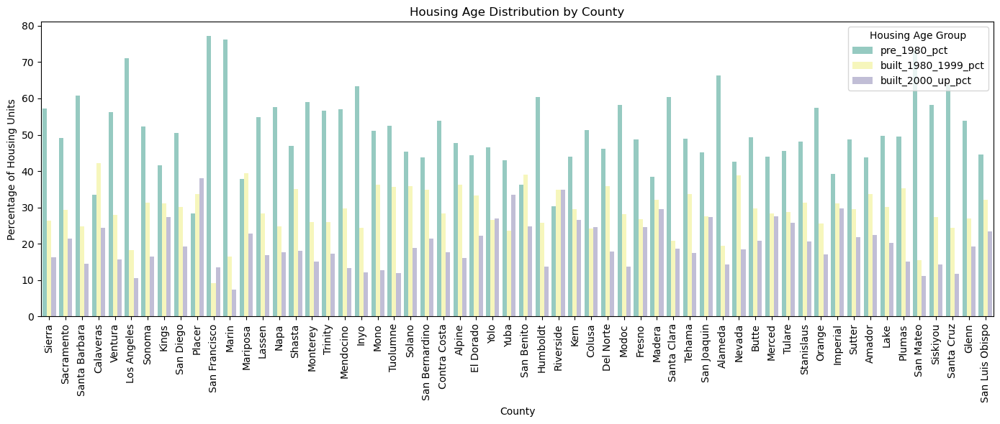

In [507]:
# Melt the data for grouped barplot
melted_age = gdf[[
    "county",
    "pre_1980_pct",
    "built_1980_1999_pct",
    "built_2000_up_pct"
]].melt(
    id_vars="county",
    var_name="housing_age_group",
    value_name="percentage"
)

# Plot
plt.figure(figsize=(14, 6))
ax = sns.barplot(
    data=melted_age,
    x="county",
    y="percentage",
    hue="housing_age_group",
    palette="Set3"
)

# Rotate county names
ax.set_xticks(range(len(gdf["county"])))
ax.set_xticklabels(gdf["county"], rotation=90)

# Labels and title
ax.set_ylabel("Percentage of Housing Units")
ax.set_xlabel("County")
ax.set_title("Housing Age Distribution by County")
plt.legend(title="Housing Age Group", loc="upper right")
plt.tight_layout()
plt.show()


>**Observations:**  
>- Many counties still have a **majority of homes built before 1980**, including **San Francisco (77%)**, **Marin (76%)**, and **Los Angeles (71%)**.
>- Counties with a **larger share of newer housing (post-2000)** include **Placer (38%)**, **Yuba (33%)**, **Riverside (34.8%)**, and **Imperial (29.8%)** — often areas with recent development or population growth.
>- Only a few counties like **Calaveras** and **San Benito** show a relatively balanced mix across all three age groups.
>
>This breakdown helps contextualize why older housing may be associated with higher EQ take-up in the next plots and correlation analysis.


In [509]:
# Top 3 counties with highest % of pre-1980 housing
gdf[["county", "pre_1980_pct", "built_1980_1999_pct", "built_2000_up_pct"]].sort_values("pre_1980_pct", ascending=False).head(3)


,county,pre_1980_pct,built_1980_1999_pct,built_2000_up_pct
10,San Francisco,77.21,9.23,13.56
11,Marin,76.11,16.46,7.43
53,San Mateo,73.33,15.44,11.23


In [510]:
# Top 3 counties with highest % of built_2000_up_pct
gdf[["county", "pre_1980_pct", "built_1980_1999_pct", "built_2000_up_pct"]].sort_values("built_2000_up_pct", ascending=False).head(3)


,county,pre_1980_pct,built_1980_1999_pct,built_2000_up_pct
9,Placer,28.34,33.62,38.05
31,Riverside,30.24,34.92,34.84
28,Yuba,42.98,23.59,33.43


---
#### ➤ Correlation with EQ Take-Up Rate
Examines how homeownership rates and housing age correlate with earthquake insurance adoption.


In [512]:
# Correlation with EQ Take-Up Rate
for col in ["owner_pct", "renter_pct", "pre_1980_pct", "built_1980_1999_pct", "built_2000_up_pct"]:
    pearson_corr = pearsonr(gdf[col], gdf["eq_takeup_pct"])[0]
    spearman_corr = spearmanr(gdf[col], gdf["eq_takeup_pct"])[0]
    print(f"{col}")
    print(f"   • Pearson  : {pearson_corr:.2f}")
    print(f"   • Spearman : {spearman_corr:.2f}\n")
    

owner_pct
   • Pearson  : -0.02
   • Spearman : -0.08

renter_pct
   • Pearson  : 0.02
   • Spearman : 0.08

pre_1980_pct
   • Pearson  : 0.22
   • Spearman : 0.36

built_1980_1999_pct
   • Pearson  : -0.01
   • Spearman : -0.13

built_2000_up_pct
   • Pearson  : -0.35
   • Spearman : -0.47



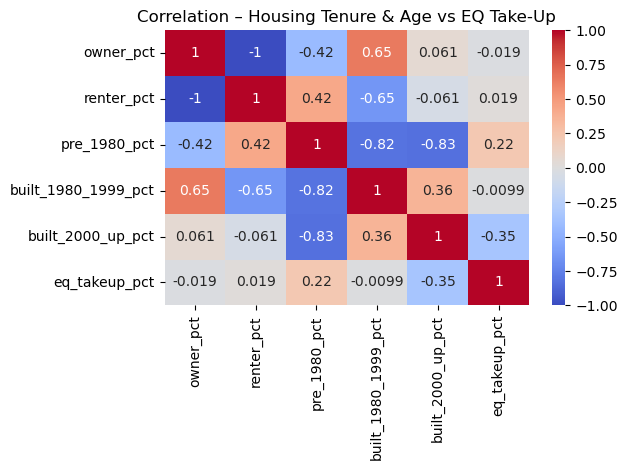

In [513]:
# Correlation Heatmap
sns.heatmap(
    gdf[["owner_pct", "renter_pct", "pre_1980_pct", "built_1980_1999_pct", "built_2000_up_pct", "eq_takeup_pct"]].corr(),
    annot=True, cmap="coolwarm", vmin=-1, vmax=1
)
plt.title("Correlation – Housing Tenure & Age vs EQ Take-Up")
plt.tight_layout()
plt.show()


>**Observation:**    
>The age of housing stock shows the strongest correlation with EQ insurance take-up:  
>- **Older homes (pre-1980)** are **positively correlated** with take-up *(Spearman: +0.36)*, suggesting that perceived risk or building code concerns may drive coverage.  
>- **Newer homes (built 2000+)** show a **negative correlation** *(Spearman: –0.47)*, possibly due to greater seismic resilience or lower risk perception.  
>- **Tenure status** *(owner vs renter)* shows little to no direct correlation with take-up in this univariate view, though it may interact with other factors.

---
#### ➤ Scatterplots: Housing Age vs EQ Take-Up Rate 
Side-by-side plots showing relationships between EQ take-up and both older and newer housing stock.


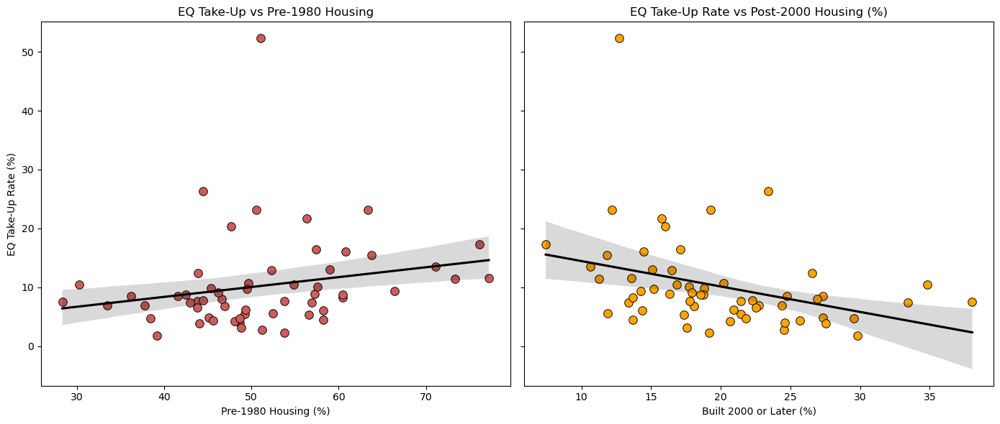

In [515]:
# Side-by-Side Scatterplots: Pre-1980 vs Post-2000
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Plot 1: Pre-1980 Housing vs EQ Take-Up
sns.scatterplot(data=gdf, x="pre_1980_pct", y="eq_takeup_pct", s=70, color="indianred", edgecolor="black", ax=axes[0])
sns.regplot(data=gdf, x="pre_1980_pct", y="eq_takeup_pct", scatter=False, color="black", ax=axes[0])
axes[0].set_title("EQ Take-Up vs Pre-1980 Housing")
axes[0].set_xlabel("Pre-1980 Housing (%)")
axes[0].set_ylabel("EQ Take-Up Rate (%)")

# # Plot 2: Built 2000+ Housing vsEQ Take-Up
sns.scatterplot(data=gdf, x="built_2000_up_pct", y="eq_takeup_pct", s=70, color="orange", edgecolor="black", ax=axes[1])
sns.regplot(data=gdf,x="built_2000_up_pct", y="eq_takeup_pct", scatter=False, color="black", ax=axes[1])
axes[1].set_title("EQ Take-Up Rate vs Post-2000 Housing (%)")
axes[1].set_xlabel("Built 2000 or Later (%)")
axes[1].set_ylabel("EQ Take-Up Rate (%)")

plt.tight_layout()
plt.show()


>**Observation**  
>These scatterplots reveal contrasting relationships between housing age and earthquake insurance behavior:
>- **Pre-1980 Housing** shows a **positive trend**: counties with more older homes tend to have **higher EQ take-up rates**. This may reflect increased awareness of structural vulnerability or stronger retrofitting and insurance outreach in older housing stock.  
>- **Post-2000 Housing** shows a **moderate negative correlation**: counties with newer housing tend to have **lower EQ take-up**, possibly due to newer homes being built to seismic codes, reducing perceived risk.
>
>This reinforces the idea that **perceived vulnerability** and **housing age** play a role in influencing insurance decisions, independent of income or ownership status.

---
#### ➤ Barplot: Housing Age vs EQ Take-Up Rate by County
County-level comparison of EQ take-up rates alongside share of older (pre-1980) and newer (post-2000) homes.


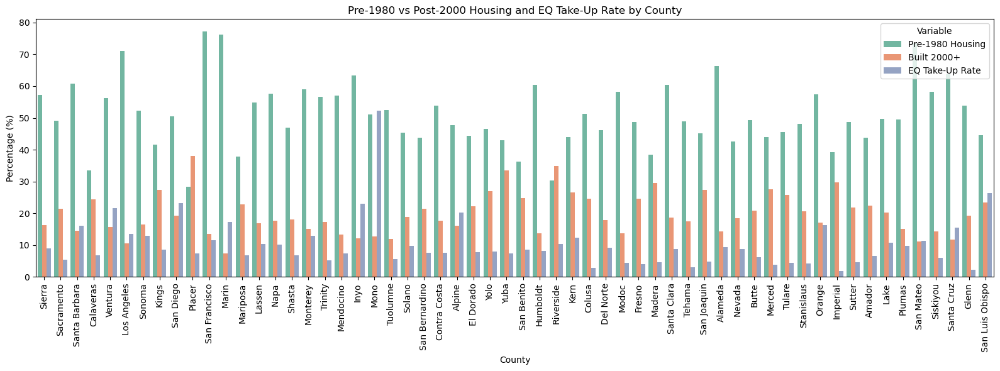

In [517]:
# Melt selected variables
melted = gdf[[
    "county",
    "pre_1980_pct",
    "built_2000_up_pct",
    "eq_takeup_pct"
]].melt(
    id_vars="county",
    var_name="variable",
    value_name="value"
)

# Rename for clarity
melted["variable"] = melted["variable"].replace({
    "pre_1980_pct": "Pre-1980 Housing",
    "built_2000_up_pct": "Built 2000+",
    "eq_takeup_pct": "EQ Take-Up Rate"
})

# Plot
plt.figure(figsize=(16, 6))
ax = sns.barplot(data=melted, x="county", y="value", hue="variable", palette="Set2")

# Customize axes
ax.set_title("Pre-1980 vs Post-2000 Housing and EQ Take-Up Rate by County")
ax.set_ylabel("Percentage (%)")
ax.set_xlabel("County")
ax.set_xticks(range(len(gdf["county"])))
ax.set_xticklabels(gdf["county"], rotation=90)

plt.legend(title="Variable", loc="upper right")
plt.tight_layout()
plt.show()


>**Observation – Housing Age vs EQ Take-Up Rate (by County)**  
>- Counties with a **higher share of pre-1980 housing** often show moderate to high EQ take-up rates, supporting the earlier finding that older housing stock may be more likely to carry earthquake insurance.
>- Conversely, **counties with a higher proportion of post-2000 housing** tend to have lower take-up rates, possibly due to newer construction being perceived as lower risk or due to changes in ownership/awareness.
>- Some counties (e.g. **San Luis Obispo, Inyo, Mono**) stand out with high EQ take-up despite varied housing age composition, suggesting that local outreach, seismic activity, or cultural factors may also play a strong role.
>- Overall, housing age patterns align with take-up behavior, reinforcing their value as predictors in modeling.

---
#### ✅ Conclusion – Housing Tenure & Age

- **No significant relationship** between housing tenure (`owner_pct` / `renter_pct`) and earthquake insurance take-up.
- **Older homes (pre-1980)** show a **positive correlation** with EQ take-up (Spearman = +0.36), suggesting that aging housing stock may increase perceived risk and drive demand.
- **Newer homes (built 2000 or later)** show a **negative correlation** with take-up (Spearman = –0.47), likely due to improved building codes and lower perceived vulnerability.
- **Middle-era homes (1980–1999)** have **negligible correlation** with take-up behavior, indicating no clear influence in either direction.


---
### 🏚️ Group 5: Housing Vacancy Types  

In this section, I examined how different types of housing vacancy relate to earthquake insurance take-up across California counties. The goal was to see whether areas with more seasonal, migrant, or other vacant housing show different insurance behavior compared to more permanently occupied housing.  

I focused on the following key variables:  

- `for_rent_pct` — share of housing units currently for rent  
- `rented_not_occupied_pct` — units rented but not yet occupied  
- `for_sale_pct` — share of housing units currently for sale  
- `sold_not_occupied_pct` — units sold but not yet occupied  
- `seasonal_pct` — seasonal or recreational housing units  
- `migrant_pct` — housing units for migrant workers  
- `other_vacant_pct` — other vacant units not classified above  

---
#### ➤ Review Summary Stats
Descriptive statistics of housing vacancy types across California counties, including seasonal units, for-rent, for-sale, migrant, and other vacant categories.


In [520]:
# Define vacancy-related variables
vacancy_cols = [
    "for_rent_pct",
    "rented_not_occupied_pct",
    "for_sale_pct",
    "sold_not_occupied_pct",
    "seasonal_pct",
    "migrant_pct",
    "other_vacant_pct"
]

gdf[vacancy_cols].describe().T
    

,count,mean,std,min,25%,50%,75%,max
for_rent_pct,58.0,15.051724,11.663878,0.0,4.350,12.70,23.575,42.9
rented_not_occupied_pct,58.0,3.375862,3.560027,0.0,1.000,2.45,5.100,22.0
for_sale_pct,58.0,6.067241,3.611259,0.5,3.650,5.50,7.550,20.1
sold_not_occupied_pct,58.0,5.131034,5.499640,0.0,2.325,4.05,6.150,35.9
seasonal_pct,58.0,40.784483,24.891419,4.5,18.400,35.60,57.800,92.5
migrant_pct,58.0,0.417241,0.705899,0.0,0.000,0.15,0.400,3.2
other_vacant_pct,58.0,29.172414,12.860381,2.4,22.050,30.35,38.125,62.6


> The summary statistics reveal a wide variation across vacancy types in California counties:
>- **Seasonal housing** shows the highest variability, with a **mean of 40.8%** and values ranging from **4.5% to 92.5%**.
>- **Other vacant units** also make up a large share, averaging **29.2%**, with some counties reaching over **60%**.
>- **For rent** and **for sale** vacancy rates are more moderate on average (**15.1%** and **6.1%**, respectively), but still show high dispersion.
>- **Migrant** and **rented-not-occupied** categories are rare overall, with medians below **3%** and many counties at **0%**.
>
>These differences suggest that vacancy composition varies dramatically across counties, especially for seasonal and other-vacant units.

---
#### ➤ Stacked Bar Chart – Vacancy Distribution by County
Visual breakdown of vacancy type composition by county, showing how seasonal, rental, and other categories contribute to total vacant housing.


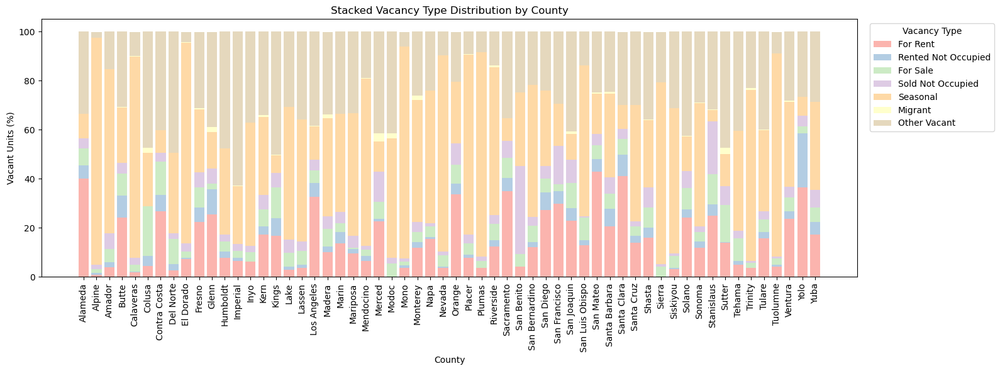

In [522]:
# Sort counties alphabetically (optional)
gdf_sorted = gdf.sort_values("county").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(16, 6))
x = range(len(gdf_sorted))

colors = {
    "for_rent_pct": "#fbb4ae",
    "rented_not_occupied_pct": "#b3cde3",
    "for_sale_pct": "#ccebc5",
    "sold_not_occupied_pct": "#decbe4",
    "seasonal_pct": "#fed9a6",
    "migrant_pct": "#ffffcc",
    "other_vacant_pct": "#e5d8bd"
}

bottom = [0] * len(gdf_sorted)

for col in vacancy_cols:
    values = gdf_sorted[col].values
    ax.bar(x, values, bottom=bottom, label=col.replace("_pct", "").replace("_", " ").title(), color=colors[col])
    bottom = [i + j for i, j in zip(bottom, values)]  

ax.set_xticks(x)
ax.set_xticklabels(gdf_sorted["county"], rotation=90)
ax.set_ylabel("Vacant Units (%)")
ax.set_xlabel("County")
ax.set_title("Stacked Vacancy Type Distribution by County")
ax.legend(title="Vacancy Type", bbox_to_anchor=(1.01, 1), loc="upper left")

plt.tight_layout()
plt.show()


>**Observation**
>- **Seasonal housing** dominates vacancy profiles in many rural counties such as Alpine, Mono, and El Dorado — often exceeding 80% of all vacant units.
>- **Other vacant units** are a major share in counties like Imperial, Sacramento, and Kings — possibly reflecting unoccupied or uninhabitable housing.
>- Urban areas (e.g., San Francisco, Santa Clara) tend to show a more **balanced mix** of vacancy types, including higher shares of rental-related vacancies.
>- This chart provides important context before evaluating how different vacancy types correlate with insurance take-up.


In [524]:
# View all vacancy percentages by county
gdf[["county"] + vacancy_cols].sample(5)


,county,for_rent_pct,rented_not_occupied_pct,for_sale_pct,sold_not_occupied_pct,seasonal_pct,migrant_pct,other_vacant_pct
6,Sonoma,11.9,2.7,3.6,2.3,50.3,0.4,28.8
53,San Mateo,42.9,5.2,5.6,4.5,16.6,0.3,24.9
28,Yuba,17.4,5.1,5.7,7.3,35.9,0.0,28.6
0,Sierra,0.0,0.0,4.1,1.2,74.1,0.0,20.5
51,Lake,2.9,1.2,5.7,5.4,54.1,0.0,30.7


---
#### ➤ Correlations with EQ Take-Up
Statistical correlations between each vacancy type and earthquake insurance take-up, using Pearson and Spearman coefficients to highlight directional trends.


In [526]:
for col in vacancy_cols:
    pearson_corr = pearsonr(gdf[col], gdf["eq_takeup_pct"])[0]
    spearman_corr = spearmanr(gdf[col], gdf["eq_takeup_pct"])[0]
    print(f"{col}")
    print(f"   • Pearson  : {pearson_corr:.2f}")
    print(f"   • Spearman : {spearman_corr:.2f}\n")


for_rent_pct
   • Pearson  : -0.02
   • Spearman : 0.07

rented_not_occupied_pct
   • Pearson  : -0.07
   • Spearman : 0.06

for_sale_pct
   • Pearson  : -0.26
   • Spearman : -0.18

sold_not_occupied_pct
   • Pearson  : -0.15
   • Spearman : -0.11

seasonal_pct
   • Pearson  : 0.30
   • Spearman : 0.23

migrant_pct
   • Pearson  : -0.29
   • Spearman : -0.39

other_vacant_pct
   • Pearson  : -0.39
   • Spearman : -0.39



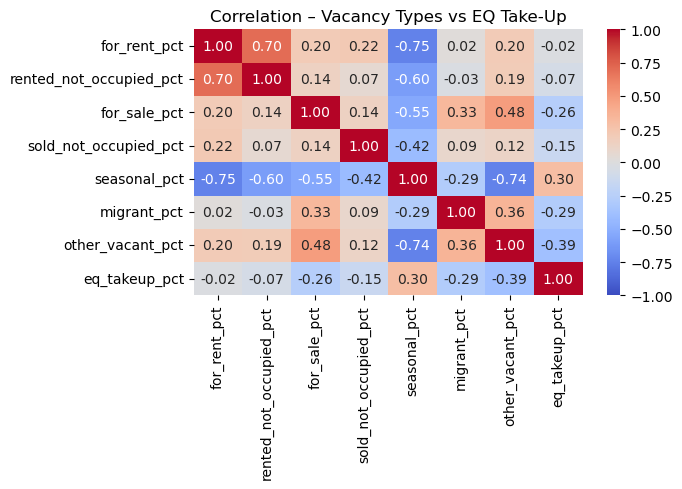

In [527]:
# Correlation Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    gdf[vacancy_cols + ["eq_takeup_pct"]].corr(),
    annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f"
)
plt.title("Correlation – Vacancy Types vs EQ Take-Up")
plt.tight_layout()
plt.show()


>The correlation analysis between vacancy types and earthquake insurance take-up rates reveals a few modest patterns:  
>- **Other vacant units** show the strongest **negative correlation** (Spearman = –0.39), suggesting that counties with a high share of undefined or miscellaneous vacancies may have lower insurance participation.
>- **Migrant housing** is also negatively correlated (Spearman = –0.39), though it's a rare category overall.
>- **Seasonal housing** shows a **positive correlation** with EQ take-up (Spearman = +0.23), indicating higher participation in areas with many vacation homes.
>- **For sale** and **sold-not-occupied** units show weak negative correlations (Pearson between –0.15 and –0.26).
>- **For rent** and **rented-not-occupied** units exhibit **minimal to no correlation**.
>
>Overall, the relationships are not strong, but suggest that **seasonal use** may increase take-up, while **vacant or transitional units** may suppress it.

---
#### ➤ Scatterplots – Vacancy Type vs EQ Take-Up Rate
Bivariate plots comparing individual vacancy types to EQ insurance take-up, identifying patterns, clusters, and outliers across counties.


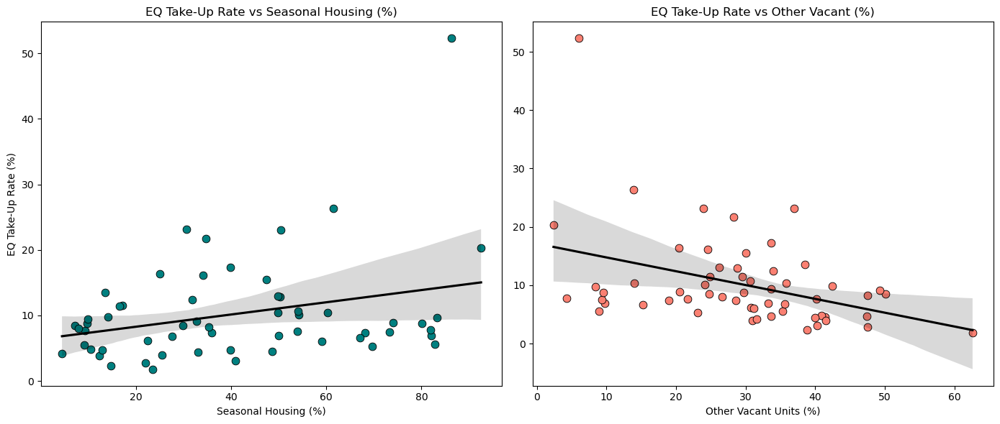

In [529]:
plt.figure(figsize=(14, 6))

# Plot 1: Seasonal Housing %
ax1 = plt.subplot(1, 2, 1)
sns.scatterplot(
    data=gdf, x="seasonal_pct", y="eq_takeup_pct",
    color="teal", s=60, edgecolor="black", ax=ax1
)
sns.regplot(
    data=gdf, x="seasonal_pct", y="eq_takeup_pct",
    scatter=False, color="black", ax=ax1
)
ax1.set_title("EQ Take-Up Rate vs Seasonal Housing (%)")
ax1.set_xlabel("Seasonal Housing (%)")
ax1.set_ylabel("EQ Take-Up Rate (%)")

# Plot 2: Other Vacant Housing %
ax2 = plt.subplot(1, 2, 2)
sns.scatterplot(
    data=gdf, x="other_vacant_pct", y="eq_takeup_pct",
    color="salmon", s=60, edgecolor="black", ax=ax2
)
sns.regplot(
    data=gdf, x="other_vacant_pct", y="eq_takeup_pct",
    scatter=False, color="black", ax=ax2
)
ax2.set_title("EQ Take-Up Rate vs Other Vacant (%)")
ax2.set_xlabel("Other Vacant Units (%)")
ax2.set_ylabel("")

plt.tight_layout()
plt.show()


>**Observation**  
>- Counties with **higher seasonal housing percentages** tend to show **moderate increases** in EQ insurance take-up — possibly reflecting second-home owners with greater financial means or higher risk awareness.
>- In contrast, counties with a **high share of “other vacant” units** (which often include abandoned or unmarketable homes) exhibit a **strong negative correlation** with take-up, indicating **low insurance penetration** in areas with housing instability.
>- These patterns reinforce the importance of housing market conditions in influencing insurance behavior.


---
#### ➤ Choropleth: Seasonal Housing as % of Vacant Units
Geospatial visualization of seasonal housing concentration, highlighting counties with high shares of vacation and second homes.


In [532]:
gdf_web = gdf.to_crs(epsg=4326)

m = folium.Map(location=[37.5, -119.5], zoom_start=6, tiles="cartodbpositron")

Choropleth(
    geo_data=gdf_web,
    name="Seasonal Vacancy %",
    data=gdf_web,
    columns=["county", "seasonal_pct"],
    key_on="feature.properties.county",
    fill_color="YlGnBu",
    fill_opacity=0.7,
    line_opacity=0.4,
    legend_name="Seasonal Housing (%) by County",
    nan_fill_color="gray",
).add_to(m)

for _, row in gdf_web.iterrows():
    folium.Marker(
        location=[row.geometry.centroid.y, row.geometry.centroid.x],
        icon=None,
        tooltip=f"{row['county']}: {row['seasonal_pct']:.1f}%",
    ).add_to(m)

folium.LayerControl().add_to(m)

m.save("../maps/map_seasonal_vacancy.html")
m


> ⚠️ *Note: Interactive Folium maps do not render in GitHub Notebooks.*  
> 👉 [Click here to view the full map](https://annapiter.github.io/earthquake-insurance-analysis/maps/map_seasonal_vacancy.html)
>
> This choropleth map highlights the **percentage of seasonal housing units** (as a share of all vacant units) across California counties.  
> - **Alpine (92.5%)**, **Mono (86.3%)**, and **Tuolumne (82.8%)** stand out with the **highest seasonal housing rates**, likely reflecting strong ties to tourism and vacation property markets.
> - Coastal and mountain regions generally have higher seasonal vacancy rates, while urban and inland counties show lower values.
> 
> This spatial pattern supports the idea that **seasonality and second homes** may influence local housing dynamics and, potentially, insurance participation.

---
#### ➤ Choropleth: Seasonal Housing % + Earthquake Insurance Take-Up Overlay
Dual-layer map combining seasonal housing rates with EQ insurance participation, offering spatial insight into potential correlations.


In [534]:
m2 = folium.Map(location=[37.5, -119.5], zoom_start=6, tiles="cartodbpositron")

# Choropleth: Seasonal housing %
Choropleth(
    geo_data=gdf_web,
    name="Seasonal Housing %",
    data=gdf_web,
    columns=["county", "seasonal_pct"],
    key_on="feature.properties.county",
    fill_color="YlGnBu",
    fill_opacity=0.7,
    line_opacity=0.3,
    legend_name="Seasonal Housing (%)",
    nan_fill_color="gray"
).add_to(m2)

# Circle Overlay: EQ Insurance Take-Up Rate
for _, row in gdf_web.iterrows():
    CircleMarker(
        location=[row.geometry.centroid.y, row.geometry.centroid.x],
        radius=row["eq_takeup_pct"] * 0.5,  # adjusted scaling
        color="crimson",
        fill=True,
        fill_opacity=0.6,
        popup=folium.Popup(
            f"<b>{row['county']}</b><br>"
            f"Seasonal Housing: {row['seasonal_pct']:.1f}%<br>"
            f"EQ Take-Up Rate: {row['eq_takeup_pct']:.1f}%",
            max_width=250
        ),
        tooltip=f"{row['county']}: {row['eq_takeup_pct']:.1f}%"
    ).add_to(m2)

# Add Layer Control
folium.LayerControl().add_to(m2)
m2.save("../maps/map_seasonal_plus_eq_takeup.html")
m2


> ⚠️ *Note: Interactive Folium maps do not render in GitHub Notebooks.*  
> 👉 [Click here to view the full map](https://annapiter.github.io/earthquake-insurance-analysis/maps/map_seasonal_plus_eq_takeup.html)
>
> This interactive map overlays **seasonal housing rates** with **earthquake insurance take-up** using choropleth and circle markers.
> - Counties like **Mono** and **Alpine** stand out with **both high seasonal housing** and **above-average take-up rates**.
> - Many rural or mountainous counties (e.g., **Plumas**, **Tuolumne**, **Calaveras**) show **high seasonal use** but **low take-up**, suggesting diverse patterns.
>
> Overall, the relationship between seasonal housing and insurance participation is **non-linear**—some high-seasonal regions insure at high rates, while others don’t. Local risk perception or second-homeowner behavior may be driving this variation.


In [536]:
# View Top 5 Counties by EQ Take-Up Rate with their Seasonal Housing %
gdf[["county", "seasonal_pct", "eq_takeup_pct"]].sort_values("eq_takeup_pct", ascending=False).head(5)


,county,seasonal_pct,eq_takeup_pct
20,Mono,86.3,52.3
57,San Luis Obispo,61.5,26.3
8,San Diego,30.7,23.2
19,Inyo,50.4,23.1
4,Ventura,34.7,21.7


In [537]:
# Bottom 5 Counties by EQ Take-Up Rate with Seasonal Housing %
gdf[["county", "seasonal_pct", "eq_takeup_pct"]].sort_values("eq_takeup_pct", ascending=True).head(5)


,county,seasonal_pct,eq_takeup_pct
48,Imperial,23.5,1.8
56,Glenn,14.7,2.3
33,Colusa,22.0,2.8
39,Tehama,40.9,3.1
44,Merced,12.3,3.9


---
#### ✅ Conclusion – Housing Vacancy Types
- **Seasonal housing share** is **positively correlated** with EQ insurance take-up.  
Several counties with high seasonal housing—like **Mono (86.3%)** and **San Luis Obispo (61.5%)**—also show **above-average take-up** (52.3% and 26.3%, respectively).
- In contrast, counties with **low take-up rates** (e.g., Imperial, Glenn, Colusa) tend to have **moderate or low seasonal housing** and may be driven by other structural or socioeconomic factors.
- **Other vacant units** show the **strongest negative correlation** with insurance take-up (Pearson and Spearman = –0.39), possibly reflecting **neglected or unused units** not actively participating in insurance markets.
- **Migrant housing** is also negatively associated with take-up (Spearman = –0.39), highlighting a disconnect between **temporary housing** and **long-term risk planning**.
- **For-sale** and **sold-not-occupied** units show **mild negative trends**, potentially due to higher turnover or uncertainty around ownership status.

---

### ✅ Summary – Part 2: Thematic Analysis of Demographic & Housing Factors

In this second phase of exploratory analysis, I grouped variables into thematic categories and explored how each influences earthquake insurance take-up (`eq_takeup_pct`) across California counties.  
All variables were normalized as **percentages** to ensure comparability across counties of different sizes.

#### Thematic Groups Analyzed:

- **Age Composition**  
  (% under 18, % over 65)  
  → Older populations show slightly higher take-up rates, but correlations are modest.  
  Balanced age structures may be more predictive than extreme age skews.

- **Race & Ethnicity**  
  (% Hispanic, % Asian, % American Indian, etc.)  
  → No group shows strong direct correlation, but **homeownership patterns** by race explain some disparities:  
  White and American Indian populations are associated with higher homeownership.  
  Hispanic and Asian populations are more likely to rent.    
  Since renters are less likely to purchase earthquake insurance, **tenure differences** may mediate the relationship.  


- **Poverty & Insurance Coverage**  
  (% below poverty line, % homeowners insurance coverage, modeled loss ratio)  
  → Higher poverty correlates with **lower take-up** (Spearman –0.45).  
  General homeowners insurance coverage also shows negative correlation.  
  Modeled earthquake risk does **not** strongly predict take-up, suggesting **risk perception ≠ risk behavior**.

- **Housing Tenure & Age**  
  (% owner vs. renter, % pre-1980, % built 2000+)  
  → No strong relationship with tenure.  
  But **older homes** show **positive correlation** with take-up (Spearman +0.36), while **newer homes** show **negative correlation** (Spearman –0.47) — likely due to perceived vulnerability.

- **Vacancy Characteristics**  
  (% seasonal, migrant, other vacant, etc.)  
  → **Seasonal housing share** is **positively correlated** with take-up.  
  Counties with high vacation/second homes (e.g., Mono, San Luis Obispo) show high EQ insurance participation.  
  → **Other vacant** and **migrant housing** show **strong negative correlations**, suggesting these units are disconnected from insurance markets.  
  → For-sale and sold-not-occupied units trend mildly negative.


#### Key Insight:

While no single variable fully explains insurance behavior, several **patterns emerge**:

- **Socioeconomic factors** (like poverty and general insurance access) play a stronger role than seismic risk alone.
- **Housing characteristics** (age, vacancy type) help identify areas with underinsurance risk.
- **Demographic effects** are nuanced and often mediated by housing tenure.

This thematic deep dive provides a robust foundation for **Part 3**, where I will explore **seismic risk variables** — such as fault proximity, intersection with fault lines, and modeled earthquake losses — to further explain variations in insurance behavior across California.


---

### 🖋️ Author & Attribution

This notebook is part of the **Earthquake Insurance Risk Analysis in California** project.  
Created and maintained by **Anna Piterskaya**  
Data Scientist | Geospatial & Risk Modeling | [GitHub: annapiter](https://github.com/annapiter)

© 2025 Anna Piterskaya. All rights reserved.

📄 This work is licensed under the **Creative Commons Attribution-NonCommercial 4.0 International License**.  
You may share or adapt this work **with attribution** and **non-commercial use only**.  
🔗 [View License Details](https://creativecommons.org/licenses/by-nc/4.0/)
